# ESC-50 — Classificação binária com Gaussian Naive Bayes

**Objetivo:** distinguir sons **normais (classes 0–19 → 0)** de sons **anômalos (classes 40–49 → 1)**.

Este notebook mantém a **extração dos atributos do projeto original** e implementa um **baseline supervisionado** com `GaussianNB`. Ao contrário de GMM/KDE treinados somente com sons normais, o Naive Bayes **aprende com exemplos de ambas as categorias**. Por isso, a comparação entre os métodos deve reconhecer essa diferença de supervisão.

**Protocolo reprodutível:** folds oficiais do ESC-50: **1–3** para treinamento e seleção de atributos, **4** para escolha dos hiperparâmetros e do limiar, **5** reservado ao teste final. Não se consulta o teste durante a otimização.

**Ordem de execução:** rode as células na sequência, de cima para baixo. O clone do ESC-50 requer conexão com a internet (por exemplo, Google Colab).

## 1. Carregamento e extração das características

As funções abaixo foram preservadas do seu notebook original (Experimento C: MFCCs, deltas, ZCR, frequência dominante, pulsos, silêncio, entropia, fluxo espectral e outras estatísticas).

In [1]:
import os
import subprocess
if not os.path.isdir('ESC-50/meta'):
    subprocess.run(['git','clone','https://github.com/karolpiczak/ESC-50.git'], check=True)
else:
    print('ESC-50 já está presente; clonagem ignorada.')

In [2]:
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import entropy
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, roc_curve

### 1. Upload do Dataset

In [3]:
caminho_csv = 'ESC-50/meta/esc50.csv'
PASTA_AUDIO = 'ESC-50/audio/'

In [4]:
df_original = pd.read_csv(caminho_csv)

Categorias
Animais (Índices 0 a 9)
0: Dog / 1: Rooster / 2: Pig / 3: Cow / 4: Frog / 5: Cat / 6: Hen / 7: Insects (flying) / 8: Sheep / 9: Crow

 Paisagens Naturais e Sons de Água (Índices 10 a 19)
 10: Rain / 11: Sea waves / 12: Crackling fire / 13: Crickets / 14: Chirping birds / 15: Water drops / 16: Wind / 17: Pouring water / 18: Toilet flush (Descarga de vaso sanitário) / 19: Thunderstorm (Tempestade com trovoada)

 Ruídos Externos / Urbanos (Índices 40 a 49)
 40: Helicopter / 41: Chainsaw / 42: Siren / 43: Car horn / 44: Engine / 45: Train / 46: Church bells / 47: Airplane / 48: Fireworks / 49: Hand saw

In [5]:
df = df_original[(df_original['target'] <= 19) | (df_original['target'] >= 40)]

In [6]:
df.head()

,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A
5,1-101296-B-19.wav,1,19,thunderstorm,False,101296,B
8,1-103298-A-9.wav,1,9,crow,False,103298,A


In [7]:
df.shape

(1200, 7)

### 2. Ajustes do Dataset

In [8]:
SR = 16000
COLUNA_ARQUIVO = "filename"

In [9]:
def estatisticas(vetor, prefixo):
    """
    Transforma uma série temporal em características por áudio.
    """
    vetor = np.asarray(vetor).flatten()

    return {
        f"{prefixo}_mean": np.mean(vetor),
        f"{prefixo}_std": np.std(vetor),
        f"{prefixo}_median": np.median(vetor),
        f"{prefixo}_min": np.min(vetor),
        f"{prefixo}_max": np.max(vetor),
    }

### 3. Experimento C: A + B

In [10]:
def extrair_experimento_C(caminho,  n_mfcc, sr=SR):

    y, sr = librosa.load(caminho, sr=sr, mono=True)

    features = {}

    # 1. MFCC
    mfcc = librosa.feature.mfcc(
        y=y,
        sr=sr,
        n_mfcc=n_mfcc
    )
    for i in range(n_mfcc):
        features.update(
            estatisticas(
                mfcc[i],
                f"mfcc_{i+1}"
            )
        )

    # 2. DELTA
    delta = librosa.feature.delta(mfcc)
    for i in range(n_mfcc):
        features.update(
            estatisticas(
                delta[i],
                f"delta_{i+1}"
            )
        )

    # 3. DELTA-DELTA
    delta_delta = librosa.feature.delta(
        mfcc,
        order=2
    )
    for i in range(n_mfcc):
        features.update(
            estatisticas(
                delta_delta[i],
                f"delta_delta_{i+1}"
            )
        )

    # 4. ZERO CROSSING RATE
    zcr = librosa.feature.zero_crossing_rate(y)[0]

    features.update(
        estatisticas(
            zcr,
            "zcr"
        )
    )

    # 5. SPECTRAL CENTROID
    centroid = librosa.feature.spectral_centroid(
        y=y,
        sr=sr
    )[0]
    features.update(
        estatisticas(
            centroid,
            "centroid"
        )
    )


    # 6. FREQUÊNCIA DOMINANTE
    espectro = np.abs(librosa.stft(y))
    frequencias = librosa.fft_frequencies(sr=sr)
    indice_dominante = np.argmax(
        espectro,
        axis=0
    )
    freq_dominante = frequencias[indice_dominante]
    features.update(estatisticas(freq_dominante, "freq_dominante"))

    # 7. PULSOS POR SEGUNDO
    # Usa onset detection.
    # Cada onset representa aproximadamente um evento/pulso.
    onset_frames = librosa.onset.onset_detect(y=y,sr=sr)
    duracao = librosa.get_duration(y=y, sr=sr)
    if duracao > 0:
        pulsos_por_segundo = len(onset_frames) / duracao
    else:
        pulsos_por_segundo = 0

    features["pulsos_por_segundo"] = pulsos_por_segundo

    # 8. SILÊNCIO
    rms = librosa.feature.rms(y=y)[0]
    threshold = np.max(rms) * 0.05
    frames_silenciosos = rms < threshold
    percentual_silencio = np.mean(
        frames_silenciosos
    )
    features["percentual_silencio"] = percentual_silencio

    # 9. ENTROPIA ESPECTRAL
    potencia = espectro ** 2
    soma = np.sum(
        potencia,
        axis=0,
        keepdims=True
    )

    # evita divisão por zero
    soma[soma == 0] = 1e-12
    probabilidade = potencia / soma

    entropia = entropy(
        probabilidade,
        axis=0
    )
    features.update(
        estatisticas(
            entropia,
            "entropia_espectral"
        )
    )

    # 10. FLUXO ESPECTRAL
    spectral_flux = librosa.onset.onset_strength(
        y=y,
        sr=sr
    )

    features.update(
        estatisticas(
            spectral_flux,
            "fluxo_espectral"
        )
    )

    return features

### 4. Dataframes Finais Gerados

In [11]:
resultados_C = []

for _, linha in df.iterrows():

    arquivo = linha[COLUNA_ARQUIVO]

    caminho = f"{PASTA_AUDIO}/{arquivo}"

    try:

        features_C = extrair_experimento_C(caminho, 5)

        # --------------------------------------------
        # Metadados
        # --------------------------------------------
        features_C["filename"] = arquivo

        # mantém a classe original
        if "target" in df.columns:
            features_C["target"] = linha["target"]

        if "category" in df.columns:
            features_C["category"] = linha["category"]

        resultados_C.append(features_C)

    except Exception as e:

        print(
            f"Erro em {arquivo}: {e}"
        )

In [12]:
df_C = pd.DataFrame(resultados_C)

print("\nExperimento C:")
print(df_C.shape)

print("\nPrimeiras colunas C:")
print(df_C.columns.tolist())


Experimento C:
(1200, 105)

Primeiras colunas C:
['mfcc_1_mean', 'mfcc_1_std', 'mfcc_1_median', 'mfcc_1_min', 'mfcc_1_max', 'mfcc_2_mean', 'mfcc_2_std', 'mfcc_2_median', 'mfcc_2_min', 'mfcc_2_max', 'mfcc_3_mean', 'mfcc_3_std', 'mfcc_3_median', 'mfcc_3_min', 'mfcc_3_max', 'mfcc_4_mean', 'mfcc_4_std', 'mfcc_4_median', 'mfcc_4_min', 'mfcc_4_max', 'mfcc_5_mean', 'mfcc_5_std', 'mfcc_5_median', 'mfcc_5_min', 'mfcc_5_max', 'delta_1_mean', 'delta_1_std', 'delta_1_median', 'delta_1_min', 'delta_1_max', 'delta_2_mean', 'delta_2_std', 'delta_2_median', 'delta_2_min', 'delta_2_max', 'delta_3_mean', 'delta_3_std', 'delta_3_median', 'delta_3_min', 'delta_3_max', 'delta_4_mean', 'delta_4_std', 'delta_4_median', 'delta_4_min', 'delta_4_max', 'delta_5_mean', 'delta_5_std', 'delta_5_median', 'delta_5_min', 'delta_5_max', 'delta_delta_1_mean', 'delta_delta_1_std', 'delta_delta_1_median', 'delta_delta_1_min', 'delta_delta_1_max', 'delta_delta_2_mean', 'delta_delta_2_std', 'delta_delta_2_median', 'delta_d

## 2. Divisão dos dados pelos folds oficiais (sem vazamento)

Nesta etapa os metadados `fold` são associados ao `df_C` pelo `filename`, sem reextrair os áudios. **Os 30 rótulos originais são mantidos somente para analisar os atributos** e, posteriormente, são mapeados para as classes binárias de interesse.

- **Treino (folds 1, 2 e 3):** sons normais **e** anômalos; empregado na seleção de atributos e ajuste do Naive Bayes.
- **Validação (fold 4):** ajuste de `var_smoothing`, probabilidades a priori e limiar.
- **Teste (fold 5):** avaliação final uma única vez.

In [13]:
import numpy as np
import pandas as pd
from sklearn.metrics import balanced_accuracy_score

# Associação segura dos folds ao resultado da extração
assert df_C['filename'].is_unique, 'Foram encontrados áudios repetidos em df_C.'
df_nb = df_C.merge(
    df_original[['filename', 'fold']],
    on='filename', how='left', validate='one_to_one'
).copy()

assert df_nb['fold'].notna().all(), 'Há áudios sem fold associado.'
assert set(df_nb['target'].unique()) == (set(range(20)) | set(range(40, 50))), (
    'Verifique a extração: classes normais (0-19) e anômalas (40-49) não estão completas.'
)

df_nb['rotulo_binario'] = (df_nb['target'] >= 40).astype(int)
treino_nb = df_nb.loc[df_nb['fold'].isin([1, 2, 3])].copy()
validacao_nb = df_nb.loc[df_nb['fold'] == 4].copy()
teste_nb = df_nb.loc[df_nb['fold'] == 5].copy()

assert not (set(treino_nb['filename']) & set(validacao_nb['filename']))
assert not (set(treino_nb['filename']) & set(teste_nb['filename']))
assert not (set(validacao_nb['filename']) & set(teste_nb['filename']))

for nome, parte in [('Treinamento',treino_nb),('Validação',validacao_nb),('Teste',teste_nb)]:
    freq = parte['rotulo_binario'].value_counts().reindex([0,1],fill_value=0)
    print(f'{nome:<14}: {len(parte):3d} áudios | normais = {freq[0]:3d} | anômalos = {freq[1]:3d}')

Treinamento   : 720 áudios | normais = 480 | anômalos = 240
Validação     : 240 áudios | normais = 160 | anômalos =  80
Teste         : 240 áudios | normais = 160 | anômalos =  80


## 3. ANOVA e Pearson usando **somente os folds de treinamento**

Aqui aplicamos a mesma lógica de seleção do projeto: **ANOVA entre as 30 classes originais**, ordenação dos atributos pelo F-score e remoção de redundâncias pela **correlação de Pearson** (|r| ≥ 0,80). Dessa forma, a seleção permanece comparável à metodologia anterior, mas não consulta os folds 4 e 5.

**Importante:** a ANOVA das 30 classes não é exatamente uma seleção otimizada para o rótulo binário; ela preserva a hipótese do experimento anterior. É uma escolha metodológica explícita para este baseline.

In [14]:
from sklearn.feature_selection import f_classif

# Selecionamos exclusivamente features numéricas presentes em df_C.
metadados = {'target', 'fold', 'rotulo_binario'}
colunas_features = [c for c in df_C.select_dtypes(include=np.number).columns if c not in metadados]

X_selecao = treino_nb[colunas_features].replace([np.inf, -np.inf], np.nan)
medianas_treino = X_selecao.median(numeric_only=True)
X_selecao = X_selecao.fillna(medianas_treino)
if X_selecao.isna().any().any():
    raise ValueError('Algumas features ficaram inteiramente vazias; examine as colunas com NaN.')

# Mesmos rótulos multiclasse (0..19 e 40..49) do experimento original
F, valores_p = f_classif(X_selecao, treino_nb['target'])
ranking_nb = (
    pd.DataFrame({'atributo':colunas_features,'F_score':F,'p_value':valores_p})
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=['F_score'])
    .sort_values('F_score',ascending=False)
    .reset_index(drop=True)
)

print('Top 15 atributos por ANOVA — apenas folds 1–3:')
display(ranking_nb.head(15))

Top 15 atributos por ANOVA — apenas folds 1–3:


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [100] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


,atributo,F_score,p_value
0,delta_delta_3_max,41.252094,4.731697e-130
1,delta_delta_1_min,39.233264,1.951060e-125
2,delta_delta_1_std,38.780777,2.208993e-124
3,fluxo_espectral_std,38.478400,1.128692e-123
4,delta_3_max,37.829824,3.830003e-122
5,fluxo_espectral_max,36.892331,6.655710e-120
6,delta_delta_3_min,35.843053,2.343824e-117
7,delta_3_std,35.776027,3.420244e-117
8,delta_delta_3_std,34.360412,1.102712e-113
9,delta_1_std,33.471843,1.934189e-111


In [15]:
limiar_correlacao = 0.80
top_30 = ranking_nb.head(30)['atributo'].tolist()
matriz_corr_nb = X_selecao[top_30].corr(method='pearson')

atributos_sem_redundancia = []
for atributo in top_30:
    # Respeita a ordem do ranking: prevalece quem tem F-score maior
    if not any(
        pd.notna(matriz_corr_nb.loc[atributo, mantido])
        and abs(matriz_corr_nb.loc[atributo, mantido]) >= limiar_correlacao
        for mantido in atributos_sem_redundancia
    ):
        atributos_sem_redundancia.append(atributo)

# Escolha dinâmica no treino (não são usados os 12 nomes calculados sobre todos os folds)
atributos_finais = atributos_sem_redundancia[:12]
if len(atributos_finais) < 12:
    print(f'Atenção: restaram {len(atributos_finais)} atributos depois de Pearson; usaremos todos.')
assert atributos_finais, 'Nenhum atributo disponível para o modelo.'

print(f'Top 30 inicial: {len(top_30)} | Após Pearson: {len(atributos_sem_redundancia)}')
print('Features efetivamente usadas pelo Naive Bayes:')
for i, nome in enumerate(atributos_finais,1):
    print(f'{i:2d}. {nome}')

display(matriz_corr_nb.loc[atributos_finais,atributos_finais].round(2))

Atenção: restaram 9 atributos depois de Pearson; usaremos todos.
Top 30 inicial: 30 | Após Pearson: 9
Features efetivamente usadas pelo Naive Bayes:
 1. delta_delta_3_max
 2. delta_delta_1_min
 3. mfcc_3_min
 4. delta_4_std
 5. mfcc_3_std
 6. mfcc_1_mean
 7. delta_delta_2_max
 8. centroid_max
 9. mfcc_2_max


,delta_delta_3_max,delta_delta_1_min,mfcc_3_min,delta_4_std,mfcc_3_std,mfcc_1_mean,delta_delta_2_max,centroid_max,mfcc_2_max
delta_delta_3_max,1.00,-0.63,-0.64,0.72,0.78,-0.44,0.62,0.39,-0.05
delta_delta_1_min,-0.63,1.00,0.35,-0.53,-0.49,0.49,-0.70,-0.38,-0.06
mfcc_3_min,-0.64,0.35,1.00,-0.53,-0.76,0.19,-0.35,-0.13,0.04
delta_4_std,0.72,-0.53,-0.53,1.00,0.61,-0.33,0.63,0.41,0.00
mfcc_3_std,0.78,-0.49,-0.76,0.61,1.00,-0.42,0.47,0.28,-0.02
mfcc_1_mean,-0.44,0.49,0.19,-0.33,-0.42,1.00,-0.45,-0.37,-0.01
delta_delta_2_max,0.62,-0.70,-0.35,0.63,0.47,-0.45,1.00,0.52,0.02
centroid_max,0.39,-0.38,-0.13,0.41,0.28,-0.37,0.52,1.00,-0.58
mfcc_2_max,-0.05,-0.06,0.04,0.00,-0.02,-0.01,0.02,-0.58,1.00


## 4. Preparação dos dados para a classificação binária

`GaussianNB` modela a distribuição de **cada atributo dentro de cada classe** como uma gaussiana e assume independência condicional entre os atributos. Pearson remove correlações lineares altas, mas **não garante independência**, portanto essa hipótese precisa ser tratada como uma aproximação.

O imputador e a transformação das features serão ajustados exclusivamente sobre o conjunto de treino. Testaremos dois tipos: `StandardScaler` e `PowerTransformer` (Yeo-Johnson), que deixa atributos assimétricos (pulsos/s, silêncio, desvios-padrão, máx/mín) mais próximos de uma gaussiana — a hipótese central do `GaussianNB`. Ambos deixam as features com variância 1, o que dá estabilidade à interpretação de `var_smoothing`.

**Dois modos de treino do `GaussianNB`:**
- `binario`: duas gaussianas por atributo (normal x anomalia). Cada "classe" mistura sons muito diferentes (cachorro, chuva, trovão... x motor, sirene, serra...), e uma única gaussiana representa mal esse "guarda-chuva".
- `30_classes`: o **mesmo** `GaussianNB`, mas treinado com os 30 rótulos originais (uma gaussiana por atributo *por som*). O score final é consolidado somando as probabilidades posteriores das classes 40–49: `P(anomalia|x) = Σ P(classe c|x), c ∈ 40..49`. É a mesma lição do GMM (modelar cada classe separadamente), só que dentro de um único modelo.

In [16]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, recall_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_curve
)
import matplotlib.pyplot as plt

X_treino = treino_nb[atributos_finais].to_numpy(dtype=float)
X_val = validacao_nb[atributos_finais].to_numpy(dtype=float)
X_teste = teste_nb[atributos_finais].to_numpy(dtype=float)
y_treino = treino_nb['rotulo_binario'].to_numpy(dtype=int)
y_treino30 = treino_nb['target'].to_numpy(dtype=int)  # 30 rótulos originais (só para o modo '30_classes')
y_val = validacao_nb['rotulo_binario'].to_numpy(dtype=int)
y_teste = teste_nb['rotulo_binario'].to_numpy(dtype=int)

# Infinitos não devem entrar no pipeline; NaNs são tratados pelo imputador.
for nome, matriz in [('treino',X_treino), ('validação',X_val), ('teste',X_teste)]:
    if np.isinf(matriz).any():
        raise ValueError(f'Encontrado +/-inf nas features de {nome}.')

print('X treino:',X_treino.shape,'| X val:',X_val.shape,'| X teste:',X_teste.shape)
print('Distribuição de rótulos: [normal, anomalia]')
print('Treino:',np.bincount(y_treino),'Validação:',np.bincount(y_val),'Teste:',np.bincount(y_teste))

def construir_naive_bayes(var_smoothing=1e-3, transformacao='potencia'):
    """Cria novo pipeline; sem vazamento entre ajuste e avaliação."""
    if transformacao == 'potencia':
        escala = PowerTransformer(method='yeo-johnson', standardize=True)
    elif transformacao == 'padrao':
        escala = StandardScaler()
    else:
        raise ValueError(f'Transformação desconhecida: {transformacao}')

    return Pipeline([
        ('imputacao', SimpleImputer(strategy='median')),
        ('padronizacao', escala),
        ('modelo', GaussianNB(var_smoothing=var_smoothing))
    ])

def prob_anomalia(modelo, X):
    """P(anomalia|x). Binário: coluna 1. 30 classes: soma das posteriores das classes 40-49."""
    p = modelo.predict_proba(X)
    c = modelo.classes_
    return p[:, 1] if len(c) == 2 else p[:, c >= 40].sum(axis=1)


X treino: (720, 9) | X val: (240, 9) | X teste: (240, 9)
Distribuição de rótulos: [normal, anomalia]
Treino: [480 240] Validação: [160  80] Teste: [160  80]


## 5. Busca de hiperparâmetros **somente na validação**

A busca é feita em **duas etapas**, para reduzir o risco de "decorar" o fold 4 (são só ~240 áudios):

1. **Modelo** (`modo`, `transformacao`, `var_smoothing`): escolhido pela **ROC-AUC de validação**, que não depende de limiar.
2. **Limiar** de P(anomalia): escolhido depois, para o modelo vencedor, no ponto da curva ROC que maximiza a **acurácia balanceada** (índice de Youden: TPR − FPR).

Observações:
- A *prior* deixou de ser hiperparâmetro: no caso binário, trocar a prior equivale a deslocar o limiar, então testar as duas só dobrava a grade sem ganho.
- `var_smoothing` é somado à variância (já em escala ~1), então valores abaixo de ~1e-3 são praticamente iguais; a grade foi deslocada para 1e-4 a 1. Com ~24 áudios por som no modo `30_classes`, as variâncias por classe são ruidosas e a regularização importa mais.
- O Naive Bayes costuma ser **superconfiante** (probabilidades perto de 0 ou 1), por isso o limiar é buscado nos scores observados, e não numa grade fixa de 0,10 a 0,90.

O fold 5 não participa de nenhuma etapa.

In [17]:
from itertools import product

smoothing_candidatos = np.logspace(-4, 0, 9)
y_fit = {'binario': y_treino, '30_classes': y_treino30}

# Etapa 1: escolher o modelo pela ROC-AUC de validação (independe do limiar)
linhas_busca, modelos_ajustados = [], {}
for modo, transf, smoothing in product(y_fit, ['padrao', 'potencia'], smoothing_candidatos):
    modelo = construir_naive_bayes(float(smoothing), transf).fit(X_treino, y_fit[modo])
    modelos_ajustados[(modo, transf, float(smoothing))] = modelo
    linhas_busca.append({'modo': modo, 'transformacao': transf, 'var_smoothing': float(smoothing),
                         'roc_auc_val': roc_auc_score(y_val, prob_anomalia(modelo, X_val))})

resultados_validacao_nb = pd.DataFrame(linhas_busca).sort_values(
    'roc_auc_val', ascending=False).reset_index(drop=True)
print('TOP 10 — configurações na validação (fold 4), por ROC-AUC:')
display(resultados_validacao_nb.head(10).round(4))
print('Melhor ROC-AUC por modo/transformação:')
display(resultados_validacao_nb.groupby(['modo', 'transformacao'])['roc_auc_val'].max().round(4))

melhor_nb = resultados_validacao_nb.iloc[0]
modo_escolhido, transf_escolhida = melhor_nb['modo'], melhor_nb['transformacao']
smoothing_escolhido = float(melhor_nb['var_smoothing'])
modelo_final_nb = modelos_ajustados[(modo_escolhido, transf_escolhida, smoothing_escolhido)]

# Etapa 2: limiar do modelo vencedor (maximiza TPR - FPR = acurácia balanceada)
fpr_v, tpr_v, limiares_v = roc_curve(y_val, prob_anomalia(modelo_final_nb, X_val))
limiar_escolhido = float(limiares_v[np.argmax(tpr_v - fpr_v)])

print('\nCONFIGURAÇÃO FINAL — DEFINIDA ANTES DE CONSULTAR O TESTE')
print('Modo:', modo_escolhido, '| Transformação:', transf_escolhida)
print('var_smoothing:', f'{smoothing_escolhido:.2e}')
print('Limiar para prever ANOMALIA:', f'{limiar_escolhido:.4g}')
print('ROC-AUC de validação:', f"{melhor_nb['roc_auc_val']:.4f}")
print('Acurácia balanceada de validação:', f'{(1 + (tpr_v - fpr_v).max()) / 2:.4f}')

TOP 10 — configurações na validação (fold 4), por ROC-AUC:


,modo,transformacao,var_smoothing,roc_auc_val
0,30_classes,potencia,0.0032,0.8911
1,30_classes,potencia,0.0003,0.8909
2,30_classes,potencia,0.0010,0.8909
3,30_classes,potencia,0.0001,0.8909
4,30_classes,potencia,0.0100,0.8908
5,30_classes,potencia,0.0316,0.8906
6,30_classes,potencia,0.1000,0.8888
7,30_classes,potencia,0.3162,0.8791
8,30_classes,padrao,0.1000,0.8777
9,30_classes,padrao,0.0316,0.8753


Melhor ROC-AUC por modo/transformação:


modo        transformacao
30_classes  padrao           0.8777
            potencia         0.8911
binario     padrao           0.7553
            potencia         0.7453
Name: roc_auc_val, dtype: float64


CONFIGURAÇÃO FINAL — DEFINIDA ANTES DE CONSULTAR O TESTE
Modo: 30_classes | Transformação: potencia
var_smoothing: 3.16e-03
Limiar para prever ANOMALIA: 0.2425
ROC-AUC de validação: 0.8911
Acurácia balanceada de validação: 0.8469


## 6. Análise da validação

Visualizar as probabilidades estimadas de anomalia no fold 4 ajuda a perceber se as duas classes ficam separadas, sem consultar o teste.

RELATÓRIO DE VALIDAÇÃO (fold 4):
              precision    recall  f1-score   support

      Normal       0.94      0.79      0.86       160
    Anomalia       0.69      0.90      0.78        80

    accuracy                           0.83       240
   macro avg       0.81      0.85      0.82       240
weighted avg       0.86      0.83      0.83       240



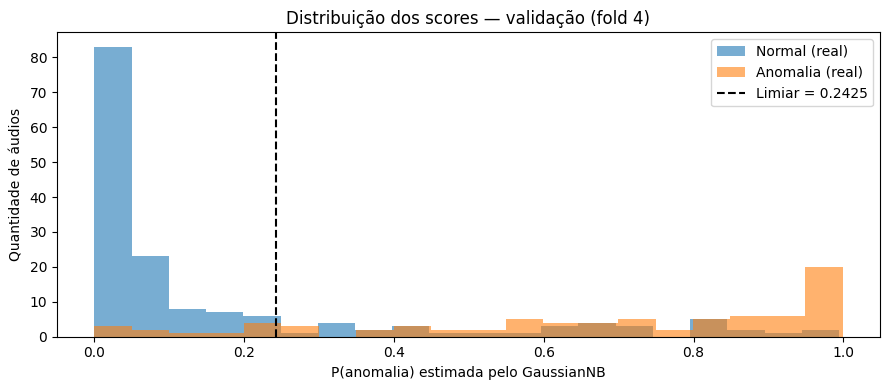

In [18]:
prob_val = prob_anomalia(modelo_final_nb, X_val)
pred_val_final = (prob_val >= limiar_escolhido).astype(int)

print('RELATÓRIO DE VALIDAÇÃO (fold 4):')
print(classification_report(y_val,pred_val_final,labels=[0,1],
                            target_names=['Normal','Anomalia'],zero_division=0))

plt.figure(figsize=(9,4))
plt.hist(prob_val[y_val==0],bins=20,alpha=.6,label='Normal (real)')
plt.hist(prob_val[y_val==1],bins=20,alpha=.6,label='Anomalia (real)')
plt.axvline(limiar_escolhido,color='black',linestyle='--',label=f'Limiar = {limiar_escolhido:.4g}')
plt.xlabel('P(anomalia) estimada pelo GaussianNB')
plt.ylabel('Quantidade de áudios')
plt.title('Distribuição dos scores — validação (fold 4)')
plt.legend()
plt.tight_layout()
plt.show()

## 7. Teste final — fold 5 (sem ajuste posterior)

O modelo, as features, os hiperparâmetros e o limiar foram congelados na etapa anterior. Este é o **único conjunto a ser usado para a avaliação final**. Caso seja necessário modificar o modelo após examinar estes resultados, o fold 5 já não pode ser considerado um teste intocado dessa nova versão.

=== NAIVE BAYES — RESULTADOS NO TESTE (fold 5) ===
Acurácia:             0.7500
Acurácia balanceada: 0.7219
F1 macro:             0.7205
Recall normal:        0.8063
Recall anomalia:      0.6375
ROC-AUC:              0.8053

RELATÓRIO DE CLASSIFICAÇÃO:
              precision    recall  f1-score   support

      Normal       0.82      0.81      0.81       160
    Anomalia       0.62      0.64      0.63        80

    accuracy                           0.75       240
   macro avg       0.72      0.72      0.72       240
weighted avg       0.75      0.75      0.75       240



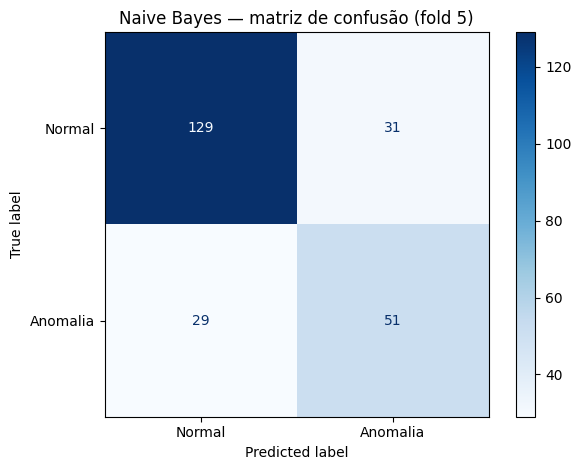

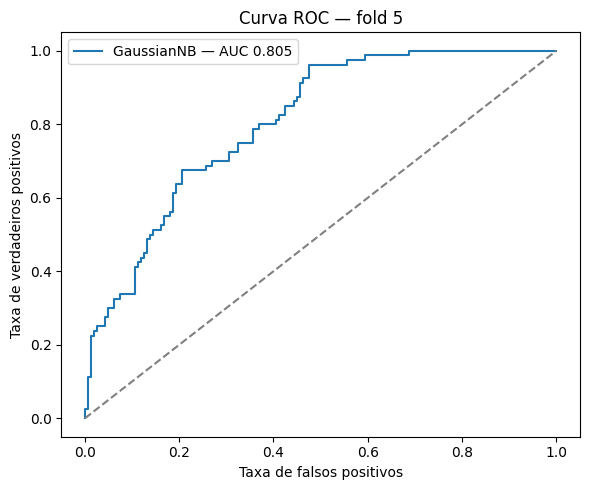

In [19]:
prob_teste = prob_anomalia(modelo_final_nb, X_teste)
pred_teste = (prob_teste >= limiar_escolhido).astype(int)

print('=== NAIVE BAYES — RESULTADOS NO TESTE (fold 5) ===')
print('Acurácia:            ',f'{accuracy_score(y_teste,pred_teste):.4f}')
print('Acurácia balanceada:',f'{balanced_accuracy_score(y_teste,pred_teste):.4f}')
print('F1 macro:            ',f'{f1_score(y_teste,pred_teste,average="macro",zero_division=0):.4f}')
print('Recall normal:       ',f'{recall_score(y_teste,pred_teste,pos_label=0,zero_division=0):.4f}')
print('Recall anomalia:     ',f'{recall_score(y_teste,pred_teste,pos_label=1,zero_division=0):.4f}')
print('ROC-AUC:             ',f'{roc_auc_score(y_teste,prob_teste):.4f}')

print('\nRELATÓRIO DE CLASSIFICAÇÃO:')
print(classification_report(y_teste,pred_teste,labels=[0,1],
                            target_names=['Normal','Anomalia'],zero_division=0))

cm = confusion_matrix(y_teste,pred_teste,labels=[0,1])
ConfusionMatrixDisplay(cm,display_labels=['Normal','Anomalia']).plot(cmap='Blues')
plt.title('Naive Bayes — matriz de confusão (fold 5)')
plt.tight_layout()
plt.show()

fpr,tpr,_ = roc_curve(y_teste,prob_teste)
plt.figure(figsize=(6,5))
plt.plot(fpr,tpr,label=f'GaussianNB — AUC {roc_auc_score(y_teste,prob_teste):.3f}')
plt.plot([0,1],[0,1],'--',color='gray')
plt.xlabel('Taxa de falsos positivos')
plt.ylabel('Taxa de verdadeiros positivos')
plt.title('Curva ROC — fold 5')
plt.legend()
plt.tight_layout()
plt.show()

## 8. Desempenho por classe original e análise dos erros

Mesmo classificando em apenas duas categorias (normal/anomalia), vale analisar **qual som original** falhou: cachorro, chuva, motor, sirene etc. Assim é possível descobrir se o desempenho global esconde dificuldades sistemáticas.

In [20]:
resultados_teste_nb = teste_nb[['filename','fold','target','category','rotulo_binario']].copy()
resultados_teste_nb['predito'] = pred_teste
resultados_teste_nb['prob_anomalia'] = prob_teste
resultados_teste_nb['acertou'] = resultados_teste_nb['rotulo_binario'] == resultados_teste_nb['predito']

por_classe_nb = (
    resultados_teste_nb.groupby(['target','category'],as_index=False)
    .agg(qtd_audios=('acertou','size'),taxa_acerto=('acertou','mean'),
         prob_media_anomalia=('prob_anomalia','mean'))
    .sort_values(['taxa_acerto','target'],ascending=[True,True])
)
print('ACERTO POR CLASSE ORIGINAL:')
display(por_classe_nb.round(4))

print('ÁUDIOS CLASSIFICADOS INCORRETAMENTE:')
display(resultados_teste_nb.loc[~resultados_teste_nb['acertou']].sort_values('prob_anomalia'))

# Baseline ingênuo: prever sempre a classe mais frequente no treino (normal=0)
y_pred_baseline = np.full_like(y_teste,fill_value=int(np.bincount(y_treino).argmax()))
comparacao_baseline = pd.DataFrame([
    {'modelo':'Sempre classe majoritária','acuracia':accuracy_score(y_teste,y_pred_baseline),
     'acuracia_balanceada':balanced_accuracy_score(y_teste,y_pred_baseline),
     'f1_macro':f1_score(y_teste,y_pred_baseline,average='macro',zero_division=0)},
    {'modelo':'GaussianNB otimizado (validação)','acuracia':accuracy_score(y_teste,pred_teste),
     'acuracia_balanceada':balanced_accuracy_score(y_teste,pred_teste),
     'f1_macro':f1_score(y_teste,pred_teste,average='macro',zero_division=0)}
])
print('COMPARAÇÃO COM BASELINE SIMPLES:')
display(comparacao_baseline.round(4))

ACERTO POR CLASSE ORIGINAL:


,target,category,qtd_audios,taxa_acerto,prob_media_anomalia
28,48,fireworks,8,0.125,0.1443
16,16,wind,8,0.250,0.4568
20,40,helicopter,8,0.250,0.2381
21,41,chainsaw,8,0.375,0.3356
2,2,pig,8,0.500,0.3900
9,9,crow,8,0.625,0.2723
12,12,crackling_fire,8,0.625,0.2409
27,47,airplane,8,0.625,0.5978
29,49,hand_saw,8,0.625,0.3871
5,5,cat,8,0.750,0.1948


ÁUDIOS CLASSIFICADOS INCORRETAMENTE:


,filename,fold,target,category,rotulo_binario,predito,prob_anomalia,acertou
1171,5-250258-A-49.wav,5,49,hand_saw,1,0,0.000398,False
1059,5-197988-A-46.wav,5,46,church_bells,1,0,0.007335,False
994,5-160614-G-48.wav,5,48,fireworks,1,0,0.025636,False
1092,5-204741-A-46.wav,5,46,church_bells,1,0,0.046929,False
1005,5-177957-B-40.wav,5,40,helicopter,1,0,0.047467,False
1130,5-216370-B-41.wav,5,41,chainsaw,1,0,0.048070,False
990,5-160614-C-48.wav,5,48,fireworks,1,0,0.052766,False
995,5-160614-H-48.wav,5,48,fireworks,1,0,0.059842,False
1054,5-197118-A-45.wav,5,45,train,1,0,0.060067,False
1181,5-253094-D-49.wav,5,49,hand_saw,1,0,0.061447,False


COMPARAÇÃO COM BASELINE SIMPLES:


,modelo,acuracia,acuracia_balanceada,f1_macro
0,Sempre classe majoritária,0.6667,0.5000,0.4000
1,GaussianNB otimizado (validação),0.7500,0.7219,0.7205


## 9. Conclusão metodológica e comparação com o GMM/KDE

**O que muda no Naive Bayes:**

1. É uma **classificação supervisionada**: ao contrário de GMM/KDE treinados só com dados normais, exige exemplos de anomalias durante o treinamento.
2. É **um único `GaussianNB`**, sem 20 modelos separados. No modo `30_classes` ele modela cada atributo por som original (uma gaussiana por classe, como no GMM por classe) e a decisão binária vem da soma das posteriores das classes anômalas; o modo `binario` fica como comparação.
3. A hipótese de **independência condicional** entre atributos é forte, especialmente em atributos relacionados a MFCCs/deltas. Pearson ajuda a eliminar correlações lineares muito altas, mas não resolve totalmente essa questão.
4. Se a pergunta científica for **detectar classes de anomalias nunca vistas**, este baseline supervisionado não mede exatamente a mesma capacidade dos modelos de novidade treinados só com sons normais.
5. Compare **acurácia balanceada, recalls, F1 macro e ROC-AUC**, mantendo mesmo fold 5. Se você quiser comparar os algoritmos **sob exatamente as mesmas features**, confirme que o outro notebook usa a mesma lista produzida apenas pelos folds 1–3.
6. O teste final foi mantido intocado durante toda a seleção e otimização. Para novas rodadas de engenharia de atributos depois de olhar para o fold 5, é necessário um protocolo de avaliação externo/nested CV para estimativas imparciais.

**Não há resultados de desempenho preenchidos artificialmente.** Execute as células com os áudios reais para obter as métricas.

## 10. XAI — Interpretando o GaussianNB (sem alterar o modelo)

Nesta seção, explicamos o **modelo `30_classes` já treinado**, usando os atributos selecionados no notebook:

1. **Global:** importância por permutação no **fold 4 (validação)**. Mostra quais atributos mais ajudam a ordenar normais e anomalias em termos de ROC-AUC. Uma importância negativa indica que embaralhar o atributo melhorou a métrica naquele teste, e não prova que o atributo seja prejudicial em geral.
2. **Local:** retirada analítica de um atributo da função de verossimilhança do GaussianNB, **sem reestimar parâmetros**. Medimos quanto cada atributo muda o *log-odds* de anomalia ao ser incluído no cálculo. Valor **positivo** favorece anomalia; **negativo** favorece normal. Esse efeito de deixar um atributo de fora é fiel à distribuição usada pelo modelo, mas **não é SHAP** e os efeitos não precisam somar o log-odds total.

A inspeção dos erros no **fold 5** é estritamente **pós-hoc**: pode gerar hipóteses, mas não devemos ajustar features, limiar ou hiperparâmetros e depois apresentar o mesmo fold 5 como teste independente. Também é importante lembrar que `predict_proba` do Naive Bayes pode ser mal calibrada.

ROC-AUC original na validação: 0.8911
Importância global (quanto maior a QUEDA na AUC, maior a influência positiva):


,atributo,queda_auc_media,desvio
0,centroid_max,0.0673,0.0114
1,mfcc_2_max,0.0609,0.0137
2,delta_delta_1_min,0.0597,0.0158
3,mfcc_3_min,0.0434,0.0173
4,mfcc_1_mean,0.0400,0.0115
5,delta_delta_3_max,0.0397,0.0103
6,delta_4_std,0.0383,0.0132
7,mfcc_3_std,0.0357,0.0183
8,delta_delta_2_max,0.0216,0.0089


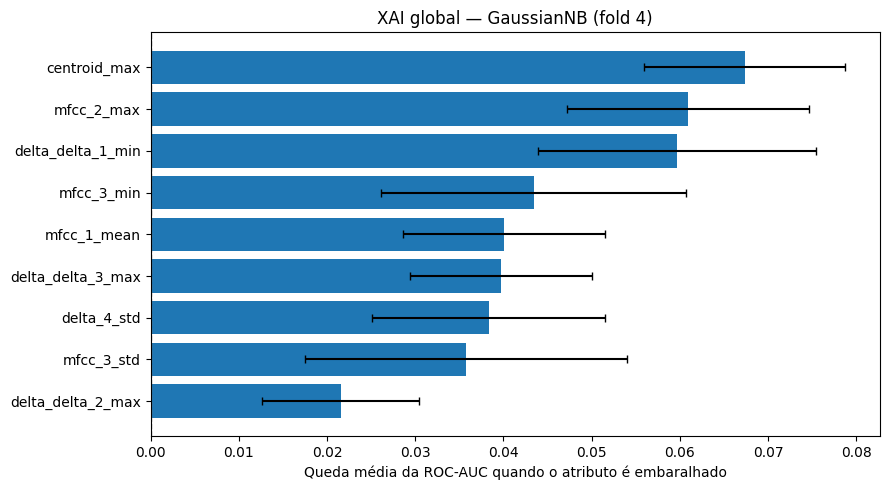

In [21]:
# XAI GLOBAL: queda de ROC-AUC ao embaralhar cada atributo no fold 4
# Reutiliza as variáveis modelo_final_nb, X_val, y_val, atributos_finais e prob_anomalia.
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def auc_binario_nb(estimator, X, y):
    # O classificador interno tem 30 classes; somamos P(classes 40-49)
    return roc_auc_score(y, prob_anomalia(estimator, X))

imp_nb = permutation_importance(
    modelo_final_nb, X_val, y_val,
    scoring=auc_binario_nb,
    n_repeats=20,
    random_state=42,
    n_jobs=1
)

importancia_global_nb = (
    pd.DataFrame({
        'atributo': atributos_finais,
        'queda_auc_media': imp_nb.importances_mean,
        'desvio': imp_nb.importances_std
    })
    .sort_values('queda_auc_media', ascending=False)
    .reset_index(drop=True)
)
print('ROC-AUC original na validação:', round(auc_binario_nb(modelo_final_nb, X_val, y_val), 4))
print('Importância global (quanto maior a QUEDA na AUC, maior a influência positiva):')
display(importancia_global_nb.round(4))

plot_nb = importancia_global_nb.sort_values('queda_auc_media')
plt.figure(figsize=(9, 5))
plt.barh(plot_nb['atributo'], plot_nb['queda_auc_media'], xerr=plot_nb['desvio'], capsize=3)
plt.axvline(0, linestyle='--', linewidth=1, color='gray')
plt.xlabel('Queda média da ROC-AUC quando o atributo é embaralhado')
plt.title('XAI global — GaussianNB (fold 4)')
plt.tight_layout()
plt.show()

OK: probabilidades reproduzidas usando os parâmetros do GaussianNB.

Áudio: 5-160614-G-48.wav | Som: fireworks
Rótulo real: Anomalia | Previsto: Normal
P(anomalia): 0.0256 | Limiar: 0.2425
Maiores influências:


,atributo,valor_original,efeito_log_odds,favorece
3,delta_4_std,3.5546,-2.3634,Normal
8,mfcc_2_max,169.5788,-0.7750,Normal
0,delta_delta_3_max,5.5814,-0.5469,Normal
7,centroid_max,2513.2817,-0.2635,Normal
1,delta_delta_1_min,-32.0919,0.2056,Anomalia
4,mfcc_3_std,18.3574,-0.1852,Normal
5,mfcc_1_mean,-251.9532,0.1299,Anomalia
6,delta_delta_2_max,7.0193,-0.0304,Normal
2,mfcc_3_min,-68.0555,-0.0033,Normal


Classes sonoras mais prováveis (entre as 30): [(2, 0.8533), (0, 0.0446), (6, 0.0257)]


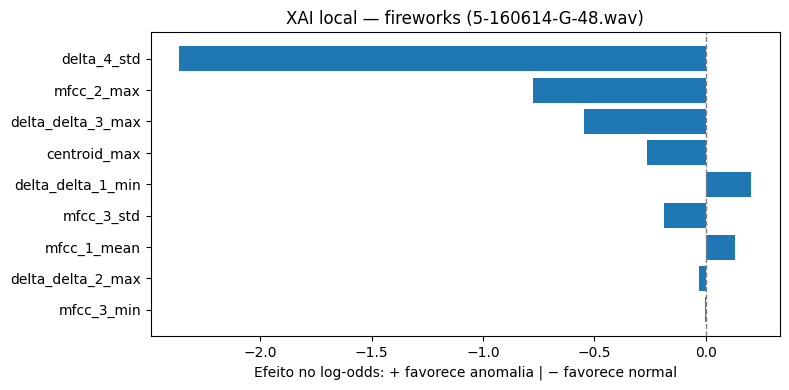


Áudio: 5-177957-B-40.wav | Som: helicopter
Rótulo real: Anomalia | Previsto: Normal
P(anomalia): 0.0475 | Limiar: 0.2425
Maiores influências:


,atributo,valor_original,efeito_log_odds,favorece
7,centroid_max,1108.9360,-0.6661,Normal
8,mfcc_2_max,149.9721,-0.6350,Normal
0,delta_delta_3_max,0.7572,-0.5962,Normal
4,mfcc_3_std,4.7400,-0.4105,Normal
5,mfcc_1_mean,-140.3038,-0.3721,Normal
6,delta_delta_2_max,1.3227,-0.3569,Normal
2,mfcc_3_min,16.4650,-0.3061,Normal
1,delta_delta_1_min,-1.8986,-0.2613,Normal
3,delta_4_std,0.5650,0.0559,Anomalia


Classes sonoras mais prováveis (entre as 30): [(16, 0.9524), (40, 0.0401), (44, 0.0072)]


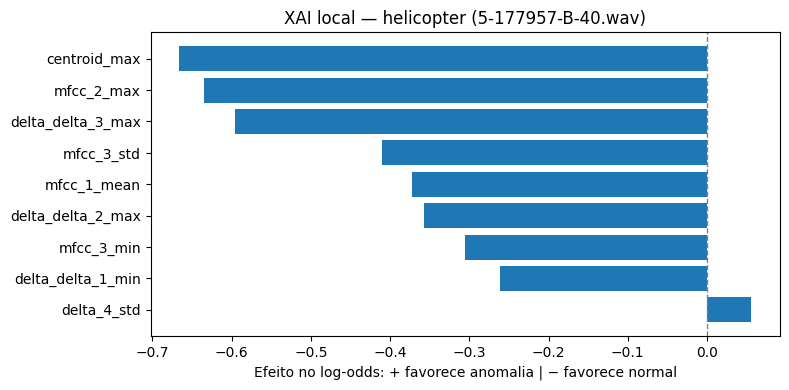


Áudio: 5-217186-A-16.wav | Som: wind
Rótulo real: Normal | Previsto: Anomalia
P(anomalia): 0.8627 | Limiar: 0.2425
Maiores influências:


,atributo,valor_original,efeito_log_odds,favorece
4,mfcc_3_std,16.7812,3.3355,Anomalia
0,delta_delta_3_max,1.1188,-1.5680,Normal
3,delta_4_std,0.7012,-0.5929,Normal
7,centroid_max,1045.6989,-0.4860,Normal
5,mfcc_1_mean,-193.8919,-0.4279,Normal
6,delta_delta_2_max,1.4311,0.1933,Anomalia
1,delta_delta_1_min,-1.7212,-0.1538,Normal
8,mfcc_2_max,189.2643,-0.1017,Normal
2,mfcc_3_min,-26.2656,-0.0955,Normal


Classes sonoras mais prováveis (entre as 30): [(40, 0.4505), (47, 0.3526), (16, 0.1348)]


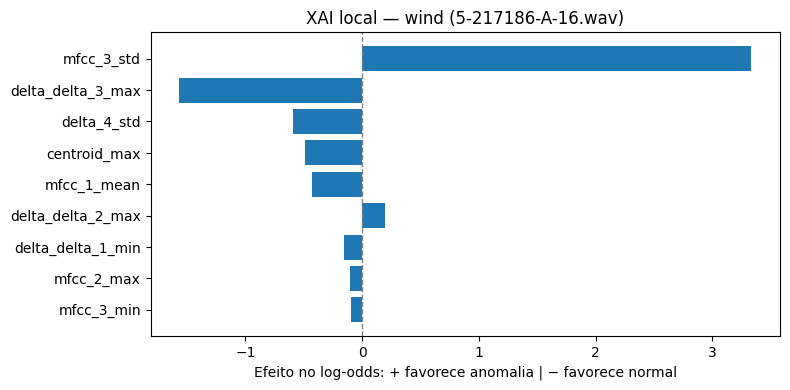

In [22]:
# XAI LOCAL: explicar erros reais de fogos, helicóptero e vento no fold 5
# IMPORTANTE: inspeção pós-hoc apenas; não otimizar o modelo sobre estes exemplos.
# O método é exato para a operação "excluir atributo j da verossimilhança",
# mas os efeitos leave-one-out não são aditivos nem equivalem a SHAP.
from scipy.special import expit, logsumexp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

nb_g = modelo_final_nb.named_steps['modelo']
if len(nb_g.classes_) != 30:
    raise ValueError('A explicação abaixo foi construída para a versão treinada com 30 classes.')

# Usa o MESMO imputador e transformador já ajustados no treinamento.
X_teste_transf = modelo_final_nb[:-1].transform(X_teste)
classes_nb = nb_g.classes_
mascara_anom = classes_nb >= 40
mascara_normal = ~mascara_anom

# Log-verossimilhança gaussiana de cada atributo em cada uma das 30 classes.
# Dimensão: [áudio, classe, atributo]
logp_feat = -0.5 * (
    np.log(2 * np.pi * nb_g.var_)[None, :, :]
    + ((X_teste_transf[:, None, :] - nb_g.theta_[None, :, :]) ** 2)
    / nb_g.var_[None, :, :]
)
log_conjunta = np.log(nb_g.class_prior_)[None, :] + logp_feat.sum(axis=2)

def log_odds_anomalia(log_conjunta_por_classe):
    return (logsumexp(log_conjunta_por_classe[..., mascara_anom], axis=-1)
            - logsumexp(log_conjunta_por_classe[..., mascara_normal], axis=-1))

# Checagem importante: a reconstrução deve reproduzir a probabilidade original.
probs_reconstruidas = expit(log_odds_anomalia(log_conjunta))
np.testing.assert_allclose(probs_reconstruidas, prob_teste, rtol=1e-6, atol=1e-8)
print('OK: probabilidades reproduzidas usando os parâmetros do GaussianNB.')

def explicar_audio(indice):
    linha = teste_nb.iloc[indice]
    log_odds_total = float(log_odds_anomalia(log_conjunta[indice]))
    efeitos = []
    for j, atributo in enumerate(atributos_finais):
        # Equivale a ignorar a verossimilhança do atributo j nas 30 classes.
        log_sem_j = log_conjunta[indice] - logp_feat[indice, :, j]
        efeito = log_odds_total - float(log_odds_anomalia(log_sem_j))
        efeitos.append(efeito)

    explicacao = pd.DataFrame({
        'atributo': atributos_finais,
        'valor_original': X_teste[indice],
        'efeito_log_odds': efeitos,
        'favorece': np.where(np.asarray(efeitos) >= 0, 'Anomalia', 'Normal')
    })
    explicacao = explicacao.sort_values(
        'efeito_log_odds', key=lambda coluna: coluna.abs(), ascending=False
    )

    print('\nÁudio:', linha['filename'], '| Som:', linha['category'])
    print('Rótulo real:', 'Anomalia' if y_teste[indice] else 'Normal',
          '| Previsto:', 'Anomalia' if pred_teste[indice] else 'Normal')
    print('P(anomalia):', round(float(prob_teste[indice]), 4),
          '| Limiar:', round(float(limiar_escolhido), 4))
    print('Maiores influências:')
    display(explicacao.round(4))

    # As três classes sonoras com maior posterior (ANTES de agregar 0/1)
    probs_30 = modelo_final_nb.predict_proba(X_teste[indice:indice+1])[0]
    principais = np.argsort(probs_30)[-3:][::-1]
    print('Classes sonoras mais prováveis (entre as 30):',
          [(int(classes_nb[k]), round(float(probs_30[k]), 4)) for k in principais])

    grafico = explicacao.iloc[::-1]
    plt.figure(figsize=(8, 4))
    plt.barh(grafico['atributo'], grafico['efeito_log_odds'])
    plt.axvline(0, color='gray', linestyle='--', linewidth=1)
    plt.xlabel('Efeito no log-odds: + favorece anomalia | − favorece normal')
    plt.title(f"XAI local — {linha['category']} ({linha['filename']})")
    plt.tight_layout()
    plt.show()
    return explicacao

# Um exemplo incorreto e de alta confiança por categoria problemática.
# Fogos/helicóptero são falsos negativos; vento é falso positivo.
categorias_investigar = ['fireworks', 'helicopter', 'wind']
categoria_por_audio = teste_nb['category'].to_numpy()
resultados_xai_local = {}
for categoria in categorias_investigar:
    candidatos = np.flatnonzero((categoria_por_audio == categoria) & (pred_teste != y_teste))
    if candidatos.size == 0:
        print(f'Nenhum erro da categoria {categoria} neste teste.')
        continue
    # Escolher o caso de erro mais confiante: menor score no falso negativo;
    # maior score no falso positivo.
    idx = (candidatos[np.argmax(prob_teste[candidatos])] if categoria == 'wind'
           else candidatos[np.argmin(prob_teste[candidatos])])
    resultados_xai_local[categoria] = explicar_audio(int(idx))


#### As classes possuem atributos semelhantes?


COMPARAÇÃO: WIND × HELICOPTER


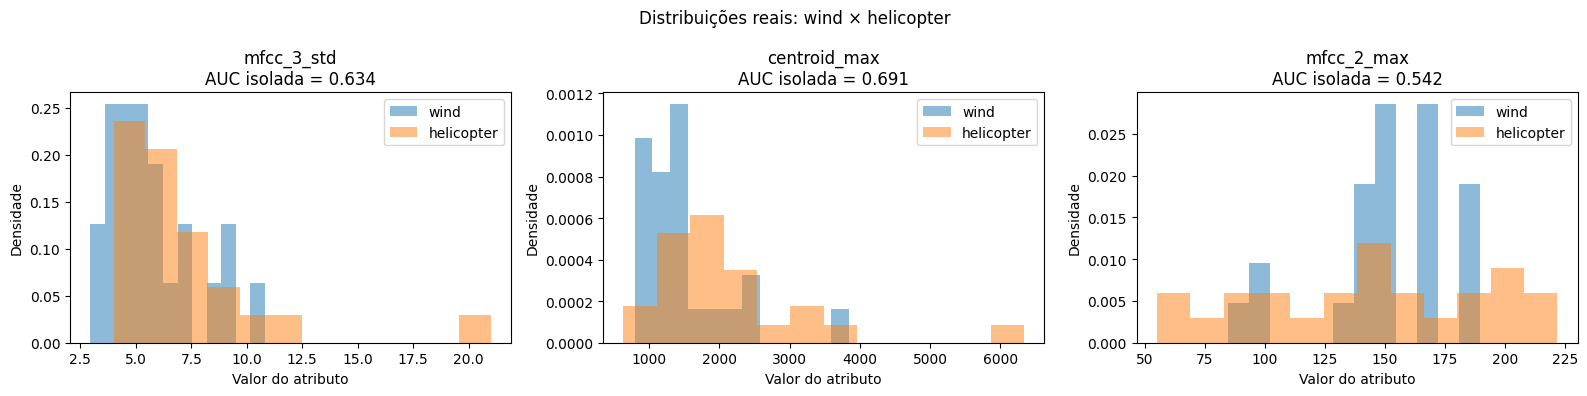


COMPARAÇÃO: PIG × FIREWORKS


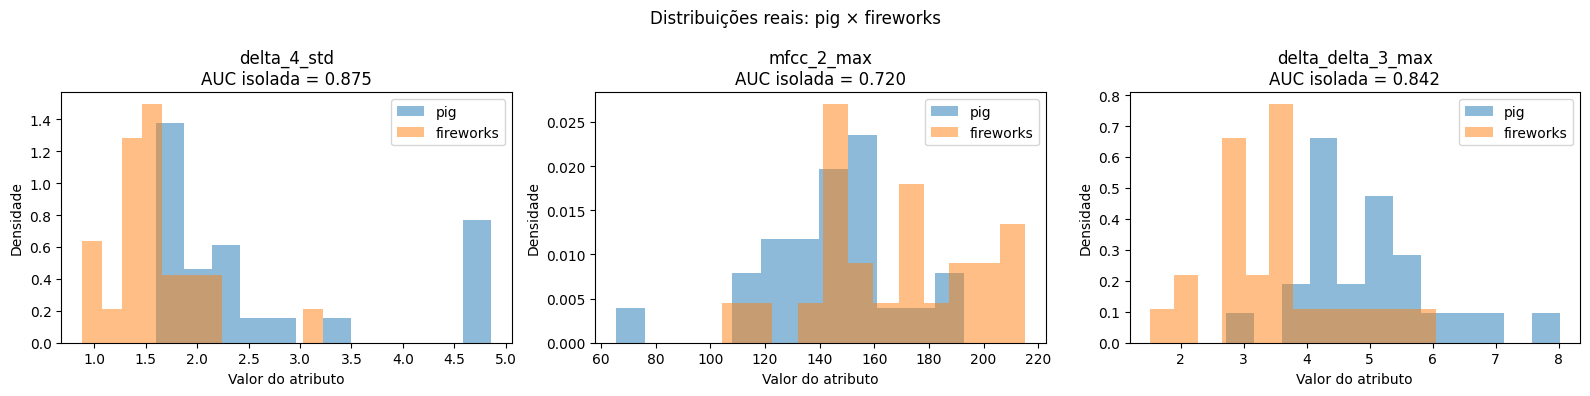


RESUMO DA SEPARABILIDADE:


,comparacao,atributo,media_A,media_B,desvio_A,desvio_B,KS,AUC_isolada
0,wind x helicopter,mfcc_3_std,5.6888,7.0306,1.9809,3.5250,0.2500,0.6337
1,wind x helicopter,centroid_max,1489.0240,2066.7468,698.3467,1163.1714,0.4583,0.6910
2,wind x helicopter,mfcc_2_max,150.8608,143.6203,26.9356,48.5997,0.2500,0.5417
3,pig x fireworks,delta_4_std,2.6506,1.5687,1.1830,0.4650,0.7083,0.8750
4,pig x fireworks,mfcc_2_max,144.7750,167.9663,26.4983,29.5460,0.4167,0.7205
5,pig x fireworks,delta_delta_3_max,4.9413,3.4954,1.0891,1.0551,0.7083,0.8420


In [23]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from sklearn.metrics import roc_auc_score

pares_xai = {
    ("wind", "helicopter"): [
        "mfcc_3_std", "centroid_max", "mfcc_2_max"
    ],
    ("pig", "fireworks"): [
        "delta_4_std", "mfcc_2_max", "delta_delta_3_max"
    ]
}

resultados_distribuicoes = []

for (classe_a, classe_b), atributos in pares_xai.items():

    print(f"\n{'='*60}")
    print(f"COMPARAÇÃO: {classe_a.upper()} × {classe_b.upper()}")
    print(f"{'='*60}")

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    for ax, atributo in zip(axes, atributos):

        a = treino_nb.loc[
            treino_nb["category"] == classe_a, atributo
        ].dropna().to_numpy(dtype=float)

        b = treino_nb.loc[
            treino_nb["category"] == classe_b, atributo
        ].dropna().to_numpy(dtype=float)

        if len(a) == 0 or len(b) == 0:
            raise ValueError(f"Dados ausentes para {atributo}")

        ks = ks_2samp(a, b).statistic

        rotulos = np.r_[
            np.zeros(len(a)),
            np.ones(len(b))
        ]
        valores = np.r_[a, b]

        auc = roc_auc_score(rotulos, valores)
        separabilidade = max(auc, 1 - auc)

        resultados_distribuicoes.append({
            "comparacao": f"{classe_a} x {classe_b}",
            "atributo": atributo,
            "media_A": np.mean(a),
            "media_B": np.mean(b),
            "desvio_A": np.std(a),
            "desvio_B": np.std(b),
            "KS": ks,
            "AUC_isolada": separabilidade
        })

        ax.hist(
            a, bins=12, alpha=0.5,
            density=True, label=classe_a
        )
        ax.hist(
            b, bins=12, alpha=0.5,
            density=True, label=classe_b
        )

        ax.set_title(
            f"{atributo}\n"
            f"AUC isolada = {separabilidade:.3f}"
        )
        ax.set_xlabel("Valor do atributo")
        ax.set_ylabel("Densidade")
        ax.legend()

    plt.suptitle(
        f"Distribuições reais: {classe_a} × {classe_b}"
    )
    plt.tight_layout()
    plt.show()

resumo_distribuicoes = pd.DataFrame(
    resultados_distribuicoes
)

print("\nRESUMO DA SEPARABILIDADE:")
display(resumo_distribuicoes.round(4))

#### O que o GaussianNB realmente aprendeu?

ERROS SELECIONADOS:


,som_real,arquivo,P_anomalia,classe_mais_provavel
0,wind,5-217186-A-16.wav,0.8627,40
1,helicopter,5-177957-B-40.wav,0.0475,16
2,pig,5-103422-A-2.wav,0.9841,43
3,fireworks,5-160614-G-48.wav,0.0256,2


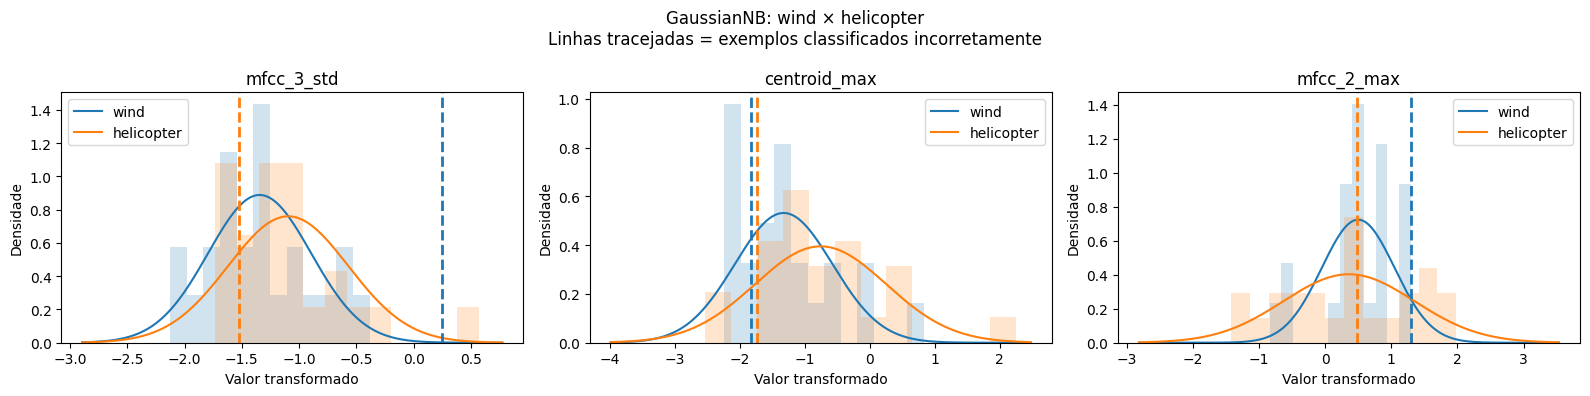

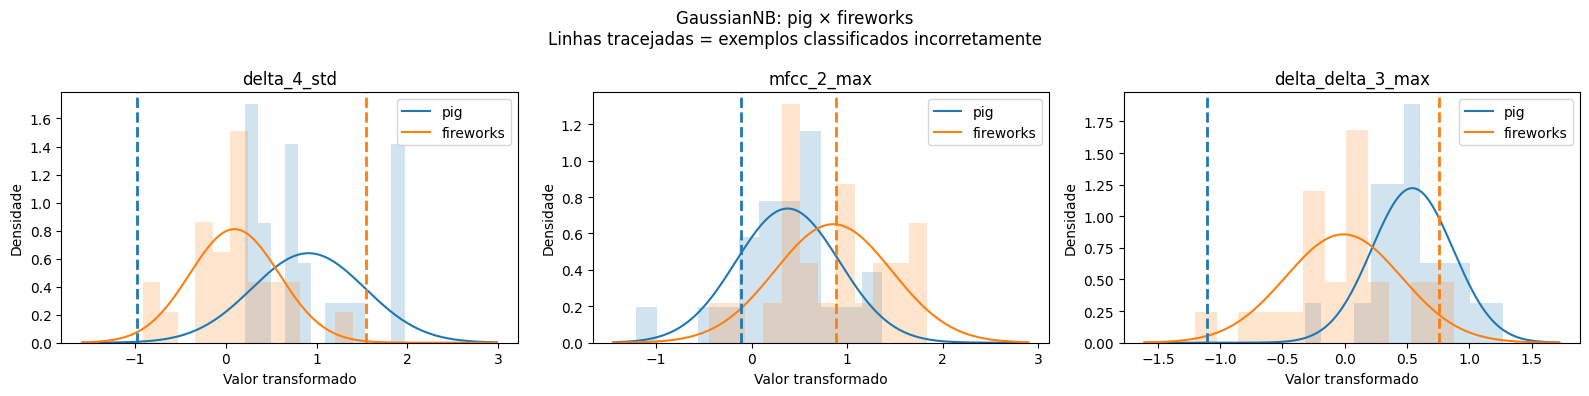

In [24]:

from scipy.stats import norm

nb_interno = modelo_final_nb.named_steps["modelo"]

if len(nb_interno.classes_) != 30:
    raise ValueError("Esta análise requer o GaussianNB de 30 classes.")

# Aplicar exatamente as transformações do modelo treinado
X_train_transf = modelo_final_nb[:-1].transform(X_treino)
X_test_transf = modelo_final_nb[:-1].transform(X_teste)

categorias_treino = treino_nb["category"].to_numpy()
categorias_teste = teste_nb["category"].to_numpy()

# Identificar um erro representativo por categoria
def encontrar_erro(categoria):
    indices = np.flatnonzero(
        (categorias_teste == categoria)
        & (pred_teste != y_teste)
    )

    if len(indices) == 0:
        return None

    if categoria in ["fireworks", "helicopter"]:
        return int(indices[np.argmin(prob_teste[indices])])

    return int(indices[np.argmax(prob_teste[indices])])


erros_selecionados = {
    categoria: encontrar_erro(categoria)
    for categoria in ["wind", "helicopter", "pig", "fireworks"]
}

resumo_erros = []

for categoria, indice in erros_selecionados.items():
    if indice is None:
        continue

    probs_30 = modelo_final_nb.predict_proba(
        X_teste[indice:indice+1]
    )[0]

    classe_mais_provavel = int(
        nb_interno.classes_[np.argmax(probs_30)]
    )

    resumo_erros.append({
        "som_real": categoria,
        "arquivo": teste_nb.iloc[indice]["filename"],
        "P_anomalia": prob_teste[indice],
        "classe_mais_provavel": classe_mais_provavel
    })

print("ERROS SELECIONADOS:")
display(pd.DataFrame(resumo_erros).round(4))


# Comparar gaussianas aprendidas e dados do treinamento
for (classe_a, classe_b), atributos in pares_xai.items():

    id_a = int(
        treino_nb.loc[
            treino_nb["category"] == classe_a, "target"
        ].iloc[0]
    )
    id_b = int(
        treino_nb.loc[
            treino_nb["category"] == classe_b, "target"
        ].iloc[0]
    )

    pos_a = np.where(nb_interno.classes_ == id_a)[0][0]
    pos_b = np.where(nb_interno.classes_ == id_b)[0][0]

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    for ax, atributo in zip(axes, atributos):

        j = atributos_finais.index(atributo)

        dados_a = X_train_transf[
            categorias_treino == classe_a, j
        ]
        dados_b = X_train_transf[
            categorias_treino == classe_b, j
        ]

        mu_a = nb_interno.theta_[pos_a, j]
        mu_b = nb_interno.theta_[pos_b, j]

        sd_a = np.sqrt(nb_interno.var_[pos_a, j])
        sd_b = np.sqrt(nb_interno.var_[pos_b, j])

        pontos = list(dados_a) + list(dados_b)

        for categoria in [classe_a, classe_b]:
            idx = erros_selecionados.get(categoria)
            if idx is not None:
                pontos.append(X_test_transf[idx, j])

        xmin = min(min(pontos), mu_a - 3*sd_a, mu_b - 3*sd_b)
        xmax = max(max(pontos), mu_a + 3*sd_a, mu_b + 3*sd_b)

        x = np.linspace(xmin - 0.2, xmax + 0.2, 400)

        ax.hist(
            dados_a, bins=12, density=True,
            alpha=0.20, color="tab:blue"
        )
        ax.hist(
            dados_b, bins=12, density=True,
            alpha=0.20, color="tab:orange"
        )

        ax.plot(
            x, norm.pdf(x, mu_a, sd_a),
            color="tab:blue",
            label=classe_a
        )

        ax.plot(
            x, norm.pdf(x, mu_b, sd_b),
            color="tab:orange",
            label=classe_b
        )

        for categoria, cor in [
            (classe_a, "tab:blue"),
            (classe_b, "tab:orange")
        ]:
            idx = erros_selecionados.get(categoria)

            if idx is not None:
                ax.axvline(
                    X_test_transf[idx, j],
                    color=cor,
                    linestyle="--",
                    linewidth=2
                )

        ax.set_title(atributo)
        ax.set_xlabel("Valor transformado")
        ax.set_ylabel("Densidade")
        ax.legend()

    plt.suptitle(
        f"GaussianNB: {classe_a} × {classe_b}\n"
        "Linhas tracejadas = exemplos classificados incorretamente"
    )
    plt.tight_layout()
    plt.show()

#### Esses erros são recorrentes?

In [25]:

import numpy as np
import pandas as pd

categorias_foco = ["wind", "helicopter", "pig", "fireworks"]

# Probabilidades das 30 classes na validação
probs_30_val = modelo_final_nb.predict_proba(X_val)
classes_nb = modelo_final_nb.classes_

# Relacionar IDs aos nomes das categorias
mapa_classes = (
    treino_nb.drop_duplicates("target")
    .set_index("target")["category"]
    .to_dict()
)

diagnostico_val = validacao_nb[
    ["filename", "target", "category", "rotulo_binario"]
].reset_index(drop=True).copy()

diagnostico_val["prob_anomalia"] = prob_anomalia(
    modelo_final_nb, X_val
)

diagnostico_val["previsto_binario"] = (
    diagnostico_val["prob_anomalia"] >= limiar_escolhido
).astype(int)

diagnostico_val["classe_mais_provavel"] = classes_nb[
    np.argmax(probs_30_val, axis=1)
]

diagnostico_val["som_mais_provavel"] = (
    diagnostico_val["classe_mais_provavel"].map(mapa_classes)
)

diagnostico_val["acertou"] = (
    diagnostico_val["rotulo_binario"]
    == diagnostico_val["previsto_binario"]
)

# Resumo por categoria
resumo = (
    diagnostico_val[
        diagnostico_val["category"].isin(categorias_foco)
    ]
    .groupby("category")
    .agg(
        total=("acertou", "size"),
        acertos=("acertou", "sum"),
        prob_media_anomalia=("prob_anomalia", "mean")
    )
)

resumo["erros"] = resumo["total"] - resumo["acertos"]
resumo["taxa_erro"] = resumo["erros"] / resumo["total"]

print("RESUMO DOS ERROS NA VALIDAÇÃO:")
display(resumo.round(4))

print("\nDETALHAMENTO DE TODOS OS ÁUDIOS:")

for categoria in categorias_foco:

    print(f"\n{'='*55}")
    print(categoria.upper())

    dados = diagnostico_val[
        diagnostico_val["category"] == categoria
    ]

    display(
        dados[
            [
                "filename",
                "prob_anomalia",
                "som_mais_provavel",
                "acertou"
            ]
        ].sort_values("prob_anomalia").round(4)
    )

RESUMO DOS ERROS NA VALIDAÇÃO:


,total,acertos,prob_media_anomalia,erros,taxa_erro
category,,,,,
fireworks,8,7,0.7927,1,0.125
helicopter,8,8,0.7556,0,0.000
pig,8,7,0.0766,1,0.125
wind,8,2,0.5676,6,0.750



DETALHAMENTO DE TODOS OS ÁUDIOS:

WIND


,filename,prob_anomalia,som_mais_provavel,acertou
82,4-163606-A-16.wav,0.0636,wind,True
83,4-163608-B-16.wav,0.0639,wind,True
45,4-144085-A-16.wav,0.3518,wind,False
43,4-144083-B-16.wav,0.6782,helicopter,False
42,4-144083-A-16.wav,0.8031,helicopter,False
44,4-144083-C-16.wav,0.8059,helicopter,False
84,4-163609-A-16.wav,0.8296,helicopter,False
85,4-163609-B-16.wav,0.9443,airplane,False



HELICOPTER


,filename,prob_anomalia,som_mais_provavel,acertou
183,4-193480-B-40.wav,0.2438,wind,True
80,4-161579-B-40.wav,0.5481,wind,True
182,4-193480-A-40.wav,0.7510,train,True
79,4-161579-A-40.wav,0.7884,car_horn,True
129,4-175000-C-40.wav,0.8446,airplane,True
128,4-175000-B-40.wav,0.9261,airplane,True
127,4-175000-A-40.wav,0.9585,helicopter,True
24,4-125929-A-40.wav,0.9841,train,True



PIG


,filename,prob_anomalia,som_mais_provavel,acertou
224,4-250869-C-2.wav,0.0003,hen,True
30,4-132383-B-2.wav,0.0248,pig,True
29,4-132383-A-2.wav,0.0277,pig,True
218,4-234644-A-2.wav,0.0304,pig,True
223,4-250869-B-2.wav,0.0358,hen,True
222,4-250869-A-2.wav,0.0468,toilet_flush,True
48,4-147240-A-2.wav,0.1160,pig,True
49,4-147240-B-2.wav,0.3312,pig,False



FIREWORKS


,filename,prob_anomalia,som_mais_provavel,acertou
6,4-119647-A-48.wav,0.1580,dog,False
7,4-119647-B-48.wav,0.2652,hen,True
11,4-119648-B-48.wav,0.9640,fireworks,True
9,4-119647-D-48.wav,0.9724,fireworks,True
8,4-119647-C-48.wav,0.9908,fireworks,True
10,4-119648-A-48.wav,0.9939,fireworks,True
13,4-119648-D-48.wav,0.9988,fireworks,True
12,4-119648-C-48.wav,0.9989,fireworks,True


In [26]:

# Agrupa arquivos pelo identificador da gravação
df_fontes = diagnostico_val.copy()

df_fontes["origem"] = (
    df_fontes["filename"].str.split("-").str[1]
)

resumo_fontes = (
    df_fontes[
        df_fontes["category"].isin(
            ["wind", "helicopter", "fireworks", "pig"]
        )
    ]
    .groupby(["category", "origem"])
    .agg(
        audios=("filename", "count"),
        erros=("acertou", lambda x: (~x).sum()),
        prob_min=("prob_anomalia", "min"),
        prob_max=("prob_anomalia", "max")
    )
    .reset_index()
)

resumo_fontes["taxa_erro"] = (
    resumo_fontes["erros"] / resumo_fontes["audios"]
)

display(
    resumo_fontes.sort_values(
        ["category", "taxa_erro"],
        ascending=[True, False]
    ).round(4)
)

,category,origem,audios,erros,prob_min,prob_max,taxa_erro
0,fireworks,119647,4,1,0.1580,0.9908,0.25
1,fireworks,119648,4,0,0.9640,0.9989,0.00
2,helicopter,125929,1,0,0.9841,0.9841,0.00
3,helicopter,161579,2,0,0.5481,0.7884,0.00
4,helicopter,175000,3,0,0.8446,0.9585,0.00
5,helicopter,193480,2,0,0.2438,0.7510,0.00
7,pig,147240,2,1,0.1160,0.3312,0.50
6,pig,132383,2,0,0.0248,0.0277,0.00
8,pig,234644,1,0,0.0304,0.0304,0.00
9,pig,250869,3,0,0.0003,0.0468,0.00


In [27]:

from scipy.stats import shapiro
import numpy as np
import pandas as pd

X_transformado = modelo_final_nb[:-1].transform(X_treino)

df_xai_treino = pd.DataFrame(
    X_transformado,
    columns=atributos_finais
)

df_xai_treino["category"] = treino_nb["category"].to_numpy()

categorias = ["wind", "helicopter", "pig", "fireworks"]

normalidade = []
correlacoes = []

for categoria in categorias:

    dados = df_xai_treino[
        df_xai_treino["category"] == categoria
    ][atributos_finais]

    # Teste de normalidade por atributo
    for atributo in atributos_finais:
        p = shapiro(dados[atributo]).pvalue

        normalidade.append({
            "categoria": categoria,
            "atributo": atributo,
            "p_shapiro": p,
            "nao_normal_p005": p < 0.05
        })

    # Correlações entre atributos dentro da classe
    matriz = dados.corr()

    for i in range(len(atributos_finais)):
        for j in range(i + 1, len(atributos_finais)):

            a = atributos_finais[i]
            b = atributos_finais[j]

            correlacoes.append({
                "categoria": categoria,
                "atributo_1": a,
                "atributo_2": b,
                "correlacao": matriz.loc[a, b]
            })

df_normalidade = pd.DataFrame(normalidade)
df_correlacoes = pd.DataFrame(correlacoes)

print("NORMALIDADE — QUANTIDADE DE ATRIBUTOS COM p < 0.05")

display(
    df_normalidade.groupby("categoria")[
        "nao_normal_p005"
    ].agg(["sum", "count"])
)

print("\nATRIBUTOS COM MAIOR EVIDÊNCIA DE NÃO NORMALIDADE:")

display(
    df_normalidade.sort_values("p_shapiro")
    .groupby("categoria")
    .head(3)
    .round(4)
)

print("\nCORRELAÇÕES MAIS FORTES POR CLASSE:")

df_correlacoes["abs_corr"] = (
    df_correlacoes["correlacao"].abs()
)

display(
    df_correlacoes.sort_values(
        "abs_corr", ascending=False
    )
    .groupby("categoria")
    .head(5)
    .round(4)
)

NORMALIDADE — QUANTIDADE DE ATRIBUTOS COM p < 0.05


,sum,count
categoria,,
fireworks,2,9
helicopter,6,9
pig,2,9
wind,6,9



ATRIBUTOS COM MAIOR EVIDÊNCIA DE NÃO NORMALIDADE:


,categoria,atributo,p_shapiro,nao_normal_p005
32,fireworks,mfcc_1_mean,0.0000,True
28,fireworks,delta_delta_1_min,0.0000,True
15,helicopter,delta_delta_2_max,0.0000,True
10,helicopter,delta_delta_1_min,0.0006,True
14,helicopter,mfcc_1_mean,0.0009,True
21,pig,delta_4_std,0.0020,True
0,wind,delta_delta_3_max,0.0021,True
6,wind,delta_delta_2_max,0.0026,True
1,wind,delta_delta_1_min,0.0028,True
23,pig,mfcc_1_mean,0.0212,True



CORRELAÇÕES MAIS FORTES POR CLASSE:


,categoria,atributo_1,atributo_2,correlacao,abs_corr
57,helicopter,delta_4_std,mfcc_3_std,0.8917,0.8917
35,wind,centroid_max,mfcc_2_max,-0.8883,0.8883
45,helicopter,delta_delta_1_min,delta_4_std,-0.8684,0.8684
2,wind,delta_delta_3_max,delta_4_std,0.8373,0.8373
0,wind,delta_delta_3_max,delta_delta_1_min,-0.8263,0.8263
9,wind,delta_delta_1_min,delta_4_std,-0.8107,0.8107
131,fireworks,delta_4_std,delta_delta_2_max,0.8028,0.8028
41,helicopter,delta_delta_3_max,delta_delta_2_max,0.7743,0.7743
59,helicopter,delta_4_std,delta_delta_2_max,0.7676,0.7676
48,helicopter,delta_delta_1_min,delta_delta_2_max,-0.7667,0.7667


In [28]:

from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score
)
import numpy as np
import pandas as pd

Xtr = pd.DataFrame(
    np.asarray(X_treino),
    columns=atributos_finais
)

Xva = pd.DataFrame(
    np.asarray(X_val),
    columns=atributos_finais
)

ytr = treino_nb["target"].to_numpy()
yva = validacao_nb["rotulo_binario"].to_numpy()
categorias_val = validacao_nb["category"].to_numpy()

resultados_ablacao = []

variantes = {"Original (9 atributos)": list(atributos_finais)}

for atributo in atributos_finais:
    variantes[f"Sem {atributo}"] = [
        a for a in atributos_finais if a != atributo
    ]

for nome, selecionados in variantes.items():

    modelo = clone(modelo_final_nb)

    modelo.fit(
        Xtr[selecionados],
        ytr
    )

    probabilidades = modelo.predict_proba(
        Xva[selecionados]
    )

    classes = modelo.named_steps["modelo"].classes_

    mascara_anomalias = np.isin(
        classes, range(40, 50)
    )

    p_anomalia = probabilidades[
        :, mascara_anomalias
    ].sum(axis=1)

    previsto = (
        p_anomalia >= limiar_escolhido
    ).astype(int)

    resultados_ablacao.append({
        "modelo": nome,
        "n_atributos": len(selecionados),
        "ROC_AUC": roc_auc_score(
            yva, p_anomalia
        ),
        "balanced_accuracy": balanced_accuracy_score(
            yva, previsto
        ),
        "erros_wind": np.sum(
            (categorias_val == "wind") &
            (previsto == 1)
        ),
        "acertos_helicopter": np.sum(
            (categorias_val == "helicopter") &
            (previsto == 1)
        ),
        "acertos_fireworks": np.sum(
            (categorias_val == "fireworks") &
            (previsto == 1)
        )
    })

df_ablacao = pd.DataFrame(resultados_ablacao)

auc_original = df_ablacao.iloc[0]["ROC_AUC"]

df_ablacao["delta_AUC"] = (
    df_ablacao["ROC_AUC"] - auc_original
)

print("RESULTADOS DA REMOÇÃO INDIVIDUAL:")

display(
    df_ablacao.sort_values(
        "ROC_AUC", ascending=False
    ).round(4)
)

RESULTADOS DA REMOÇÃO INDIVIDUAL:


,modelo,n_atributos,ROC_AUC,balanced_accuracy,erros_wind,acertos_helicopter,acertos_fireworks,delta_AUC
5,Sem mfcc_3_std,8,0.9034,0.8469,6,8,8,0.0123
0,Original (9 atributos),9,0.8911,0.8469,6,8,7,0.0000
1,Sem delta_delta_3_max,8,0.8855,0.8375,6,8,7,-0.0055
7,Sem delta_delta_2_max,8,0.8830,0.8250,6,7,7,-0.0080
6,Sem mfcc_1_mean,8,0.8802,0.8031,6,7,6,-0.0109
4,Sem delta_4_std,8,0.8787,0.8188,6,7,6,-0.0124
2,Sem delta_delta_1_min,8,0.8782,0.8000,6,8,6,-0.0129
3,Sem mfcc_3_min,8,0.8764,0.8188,6,8,6,-0.0147
8,Sem centroid_max,8,0.8720,0.8062,6,7,6,-0.0191
9,Sem mfcc_2_max,8,0.8680,0.8000,6,7,6,-0.0230


## Otimização de Naive Bayes

In [29]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler, PowerTransformer, QuantileTransformer
)
from sklearn.decomposition import PCA
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    roc_auc_score, roc_curve,
    balanced_accuracy_score
)
import numpy as np
import pandas as pd

# 1. Oito atributos candidatos
atributos_8 = [
    a for a in atributos_finais
    if a != "mfcc_3_std"
]

assert len(atributos_8) == 8

# 2. Criar as variantes do GaussianNB
def criar_nb_otimizado(transformacao, usar_pca, smoothing):

    if transformacao == "padrao":
        escala = StandardScaler()

    elif transformacao == "potencia":
        escala = PowerTransformer(
            method="yeo-johnson"
        )

    elif transformacao == "quantile":
        escala = QuantileTransformer(
            n_quantiles=100,
            output_distribution="normal",
            random_state=42
        )

    etapas = [
        ("imputacao", SimpleImputer(strategy="median")),
        ("escala", escala)
    ]

    if usar_pca:
        etapas.append((
            "pca",
            PCA(whiten=True, random_state=42)
        ))

    etapas.append((
        "modelo",
        GaussianNB(var_smoothing=smoothing)
    ))

    return Pipeline(etapas)


# 3. Configurações
variantes = [
    ("padrao", False),
    ("potencia", False),
    ("quantile", False),
    ("potencia", True),
    ("quantile", True)
]

smoothings = np.logspace(-4, 0, 5)

X_cv = treino_nb[atributos_8].to_numpy(dtype=float)
y_cv = treino_nb["target"].to_numpy(dtype=int)
y_cv_bin = treino_nb["rotulo_binario"].to_numpy(dtype=int)
folds_cv = treino_nb["fold"].to_numpy()

resultados_otimizacao = []

# 4. Validação cruzada nos folds 1, 2 e 3
for transformacao, usar_pca in variantes:

    for smoothing in smoothings:

        scores_oof = np.zeros(len(y_cv))

        for fold in [1, 2, 3]:

            idx_treino = folds_cv != fold
            idx_validacao = folds_cv == fold

            modelo = criar_nb_otimizado(
                transformacao,
                usar_pca,
                float(smoothing)
            )

            modelo.fit(
                X_cv[idx_treino],
                y_cv[idx_treino]
            )

            scores_oof[idx_validacao] = prob_anomalia(
                modelo,
                X_cv[idx_validacao]
            )

        auc = roc_auc_score(y_cv_bin, scores_oof)

        # Limiar escolhido nas predições fora do treino
        fpr, tpr, thresholds = roc_curve(
            y_cv_bin, scores_oof
        )

        indices_validos = np.flatnonzero(
            np.isfinite(thresholds)
        )

        melhor_idx = indices_validos[
            np.argmax(
                (tpr - fpr)[indices_validos]
            )
        ]

        limiar = float(thresholds[melhor_idx])

        preds = (scores_oof >= limiar).astype(int)

        bal_acc = balanced_accuracy_score(
            y_cv_bin, preds
        )

        resultados_otimizacao.append({
            "transformacao": transformacao,
            "PCA": usar_pca,
            "smoothing": smoothing,
            "ROC_AUC_CV": auc,
            "balanced_acc_CV": bal_acc,
            "limiar_CV": limiar
        })

df_otimizacao_nb = pd.DataFrame(
    resultados_otimizacao
)

df_otimizacao_nb = df_otimizacao_nb.sort_values(
    ["balanced_acc_CV", "ROC_AUC_CV"],
    ascending=False
).reset_index(drop=True)

print("TOP 10 CONFIGURAÇÕES:")
display(df_otimizacao_nb.head(10).round(4))

melhor_config = df_otimizacao_nb.iloc[0]

print("\nCONFIGURAÇÃO VENCEDORA:")
print(melhor_config)

TOP 10 CONFIGURAÇÕES:


,transformacao,PCA,smoothing,ROC_AUC_CV,balanced_acc_CV,limiar_CV
0,quantile,True,1.0000,0.8181,0.7594,0.3819
1,potencia,True,1.0000,0.8195,0.7573,0.3782
2,quantile,True,0.1000,0.8231,0.7385,0.4805
3,quantile,True,0.0100,0.8212,0.7365,0.4599
4,quantile,True,0.0010,0.8205,0.7365,0.4735
5,quantile,True,0.0001,0.8205,0.7354,0.5135
6,potencia,True,0.1000,0.8068,0.7323,0.2306
7,potencia,True,0.0100,0.7982,0.7250,0.2676
8,potencia,True,0.0001,0.7970,0.7250,0.3585
9,potencia,True,0.0010,0.7970,0.7250,0.2534



CONFIGURAÇÃO VENCEDORA:
transformacao      quantile
PCA                    True
smoothing               1.0
ROC_AUC_CV         0.818064
balanced_acc_CV    0.759375
limiar_CV          0.381859
Name: 0, dtype: object


In [30]:

from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    accuracy_score,
    f1_score,
    recall_score,
    confusion_matrix,
    classification_report
)

# 1. Treinar vencedor
modelo_nb_otimizado = criar_nb_otimizado(
    melhor_config["transformacao"],
    bool(melhor_config["PCA"]),
    float(melhor_config["smoothing"])
)

modelo_nb_otimizado.fit(
    treino_nb[atributos_8].to_numpy(dtype=float),
    treino_nb["target"].to_numpy(dtype=int)
)

# 2. Avaliar validação (fold 4)
X_val_8 = validacao_nb[atributos_8].to_numpy(dtype=float)

prob_val_otimizado = prob_anomalia(
    modelo_nb_otimizado, X_val_8
)

limiar_otimizado = float(melhor_config["limiar_CV"])

pred_val_otimizado = (
    prob_val_otimizado >= limiar_otimizado
).astype(int)

# 3. Comparação com modelo original
prob_original = prob_anomalia(
    modelo_final_nb, X_val
)

pred_original = (
    prob_original >= limiar_escolhido
).astype(int)

categorias_val = validacao_nb["category"].to_numpy()

def avaliar_modelo(nome, probabilidades, predicoes):

    return {
        "modelo": nome,
        "ROC_AUC": roc_auc_score(
            y_val, probabilidades
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_val, predicoes
        ),
        "acuracia": accuracy_score(
            y_val, predicoes
        ),
        "F1_macro": f1_score(
            y_val, predicoes, average="macro"
        ),
        "recall_anomalia": recall_score(
            y_val, predicoes, pos_label=1
        ),
        "erros_wind": int(np.sum(
            (categorias_val == "wind") &
            (predicoes == 1)
        ))
    }

comparacao_nb = pd.DataFrame([
    avaliar_modelo(
        "Original (9 atributos)",
        prob_original,
        pred_original
    ),
    avaliar_modelo(
        "Otimizado (8 atributos)",
        prob_val_otimizado,
        pred_val_otimizado
    )
])

print("COMPARAÇÃO NA VALIDAÇÃO (FOLD 4):")
display(comparacao_nb.round(4))

print("\nLIMIAR ORIGINAL:", limiar_escolhido)
print("LIMIAR OTIMIZADO:", limiar_otimizado)

print("\nRELATÓRIO DO MODELO OTIMIZADO:")
print(classification_report(
    y_val,
    pred_val_otimizado,
    target_names=["Normal", "Anomalia"]
))

print("\nMATRIZ DE CONFUSÃO:")
print(confusion_matrix(
    y_val, pred_val_otimizado
))

COMPARAÇÃO NA VALIDAÇÃO (FOLD 4):


,modelo,ROC_AUC,balanced_accuracy,acuracia,F1_macro,recall_anomalia,erros_wind
0,Original (9 atributos),0.8911,0.8469,0.8292,0.8197,0.9000,6
1,Otimizado (8 atributos),0.8478,0.7719,0.7750,0.7578,0.7625,6



LIMIAR ORIGINAL: 0.2424770143386432
LIMIAR OTIMIZADO: 0.3818589272786892

RELATÓRIO DO MODELO OTIMIZADO:
              precision    recall  f1-score   support

      Normal       0.87      0.78      0.82       160
    Anomalia       0.64      0.76      0.69        80

    accuracy                           0.78       240
   macro avg       0.75      0.77      0.76       240
weighted avg       0.79      0.78      0.78       240


MATRIZ DE CONFUSÃO:
[[125  35]
 [ 19  61]]


A combinação QuantileTransformer + PCA + GaussianNB não resolveu o problema. Mesmo reduzindo correlações lineares, perdemos informação discriminativa.
Minha proposta: testar outra variante de Naive Bayes
Até agora usamos GaussianNB, que pressupõe distribuições gaussianas. Como encontramos evidências de não normalidade, podemos experimentar o CategoricalNB com discretização dos atributos.
A ideia é transformar atributos contínuos em faixas, sem exigir que sigam curvas gaussianas.
Vamos comparar:
- GaussianNB original (9 atributos).
- GaussianNB sem mfcc_3_std (8 atributos).
- CategoricalNB com 8 e 9 atributos, diferentes quantidades de faixas e suavizações.
A escolha será feita nos folds 1–3, usando o fold 4 apenas para comparação.

In [31]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import (
    roc_auc_score, roc_curve,
    balanced_accuracy_score
)

atributos_9 = list(atributos_finais)
atributos_8 = [
    a for a in atributos_9 if a != "mfcc_3_std"
]

def criar_categorical(bins, alpha):
    return Pipeline([
        ("imputacao", SimpleImputer(strategy="median")),
        ("discretizacao", KBinsDiscretizer(
            n_bins=bins,
            encode="ordinal",
            strategy="quantile"
        )),
        ("modelo", CategoricalNB(alpha=alpha))
    ])

def prob_anomalia_nb(modelo, X):
    probabilidades = modelo.predict_proba(X)
    mascara = np.isin(modelo.classes_, range(40, 50))
    return probabilidades[:, mascara].sum(axis=1)

configuracoes = []

# GaussianNB de referência, mantendo seus parâmetros
for nome, atributos in [
    ("GaussianNB_9", atributos_9),
    ("GaussianNB_8", atributos_8)
]:
    configuracoes.append({
        "nome": nome,
        "tipo": "gaussian",
        "atributos": atributos,
        "bins": None,
        "alpha": None
    })

# Diferentes discretizações para o CategoricalNB
for atributos in [atributos_8, atributos_9]:
    for bins in [3, 5]:
        for alpha in [0.5, 1.0, 3.0]:
            configuracoes.append({
                "nome": f"CategoricalNB_{len(atributos)}",
                "tipo": "categorical",
                "atributos": atributos,
                "bins": bins,
                "alpha": alpha
            })

def construir_modelo(config):
    if config["tipo"] == "gaussian":
        return clone(modelo_final_nb)

    return criar_categorical(
        config["bins"], config["alpha"]
    )

y_cv = treino_nb["target"].to_numpy(dtype=int)
y_cv_bin = (y_cv >= 40).astype(int)
folds = treino_nb["fold"].to_numpy()

resultados = []

for config in configuracoes:

    atributos = config["atributos"]
    X = treino_nb[atributos].to_numpy(dtype=float)

    probs_oof = np.zeros(len(y_cv))

    for fold in [1, 2, 3]:
        idx_tr = folds != fold
        idx_va = folds == fold

        modelo = construir_modelo(config)
        modelo.fit(X[idx_tr], y_cv[idx_tr])

        probs_oof[idx_va] = prob_anomalia_nb(
            modelo, X[idx_va]
        )

    auc = roc_auc_score(y_cv_bin, probs_oof)

    fpr, tpr, limiares = roc_curve(
        y_cv_bin, probs_oof
    )

    validos = np.flatnonzero(np.isfinite(limiares))
    melhor_idx = validos[
        np.argmax((tpr - fpr)[validos])
    ]

    limiar = float(limiares[melhor_idx])
    pred = (probs_oof >= limiar).astype(int)

    resultados.append({
        "nome": config["nome"],
        "atributos": len(atributos),
        "bins": config["bins"],
        "alpha": config["alpha"],
        "ROC_AUC_CV": auc,
        "balanced_acc_CV": balanced_accuracy_score(
            y_cv_bin, pred
        ),
        "limiar": limiar,
        "config": config
    })

df_busca_nb = pd.DataFrame(resultados)

df_busca_nb = df_busca_nb.sort_values(
    ["balanced_acc_CV", "ROC_AUC_CV"],
    ascending=False
).reset_index(drop=True)

print("RESULTADOS DA BUSCA:")
display(
    df_busca_nb.drop(columns="config")
    .round(4)
)

melhor_config_nb = df_busca_nb.iloc[0]["config"]
melhor_limiar_nb = df_busca_nb.iloc[0]["limiar"]

print("\nMELHOR CONFIGURAÇÃO:")
print(melhor_config_nb)

RESULTADOS DA BUSCA:


,nome,atributos,bins,alpha,ROC_AUC_CV,balanced_acc_CV,limiar
0,CategoricalNB_8,8,5.0,3.0,0.7630,0.7208,0.2404
1,CategoricalNB_9,9,5.0,3.0,0.7689,0.7146,0.1816
2,CategoricalNB_9,9,5.0,1.0,0.7655,0.7146,0.1526
3,CategoricalNB_9,9,3.0,3.0,0.7571,0.7146,0.2100
4,CategoricalNB_9,9,3.0,1.0,0.7561,0.7125,0.1898
5,CategoricalNB_8,8,3.0,1.0,0.7550,0.7115,0.2119
6,CategoricalNB_9,9,3.0,0.5,0.7541,0.7115,0.1599
7,CategoricalNB_9,9,5.0,0.5,0.7631,0.7104,0.1888
8,CategoricalNB_8,8,3.0,0.5,0.7537,0.7104,0.1871
9,CategoricalNB_8,8,5.0,0.5,0.7560,0.7094,0.1583



MELHOR CONFIGURAÇÃO:
{'nome': 'CategoricalNB_8', 'tipo': 'categorical', 'atributos': ['delta_delta_3_max', 'delta_delta_1_min', 'mfcc_3_min', 'delta_4_std', 'mfcc_1_mean', 'delta_delta_2_max', 'centroid_max', 'mfcc_2_max'], 'bins': 5, 'alpha': 3.0}


In [32]:

from sklearn.metrics import (
    roc_auc_score, balanced_accuracy_score,
    accuracy_score, f1_score, recall_score,
    confusion_matrix, classification_report
)

atributos_vencedor = melhor_config_nb["atributos"]

modelo_nb_vencedor = construir_modelo(melhor_config_nb)

modelo_nb_vencedor.fit(
    treino_nb[atributos_vencedor].to_numpy(dtype=float),
    treino_nb["target"].to_numpy(dtype=int)
)

X_validacao_vencedor = validacao_nb[
    atributos_vencedor
].to_numpy(dtype=float)

y_real = validacao_nb[
    "rotulo_binario"
].to_numpy(dtype=int)

prob_vencedor = prob_anomalia_nb(
    modelo_nb_vencedor,
    X_validacao_vencedor
)

pred_vencedor = (
    prob_vencedor >= melhor_limiar_nb
).astype(int)

# Referência original
prob_original = prob_anomalia_nb(
    modelo_final_nb,
    validacao_nb[atributos_9].to_numpy(dtype=float)
)

pred_original = (
    prob_original >= limiar_escolhido
).astype(int)

def avaliar(nome, prob, pred):
    return {
        "modelo": nome,
        "ROC_AUC": roc_auc_score(y_real, prob),
        "balanced_accuracy": balanced_accuracy_score(
            y_real, pred
        ),
        "acuracia": accuracy_score(y_real, pred),
        "F1_macro": f1_score(
            y_real, pred, average="macro"
        ),
        "recall_anomalia": recall_score(y_real, pred),
        "erros_wind": int(np.sum(
            (validacao_nb["category"] == "wind") &
            (pred == 1)
        ))
    }

comparacao_final = pd.DataFrame([
    avaliar(
        "GaussianNB original",
        prob_original, pred_original
    ),
    avaliar(
        "Naive Bayes candidato",
        prob_vencedor, pred_vencedor
    )
])

print("COMPARAÇÃO NO FOLD 4:")
display(comparacao_final.round(4))

print("\nMATRIZ DE CONFUSÃO DO CANDIDATO:")
print(confusion_matrix(y_real, pred_vencedor))

print("\nRELATÓRIO:")
print(classification_report(
    y_real, pred_vencedor,
    target_names=["Normal", "Anomalia"]
))

COMPARAÇÃO NO FOLD 4:


,modelo,ROC_AUC,balanced_accuracy,acuracia,F1_macro,recall_anomalia,erros_wind
0,GaussianNB original,0.8911,0.8469,0.8292,0.8197,0.9000,6
1,Naive Bayes candidato,0.8448,0.7312,0.6875,0.6835,0.8625,8



MATRIZ DE CONFUSÃO DO CANDIDATO:
[[96 64]
 [11 69]]

RELATÓRIO:
              precision    recall  f1-score   support

      Normal       0.90      0.60      0.72       160
    Anomalia       0.52      0.86      0.65        80

    accuracy                           0.69       240
   macro avg       0.71      0.73      0.68       240
weighted avg       0.77      0.69      0.70       240



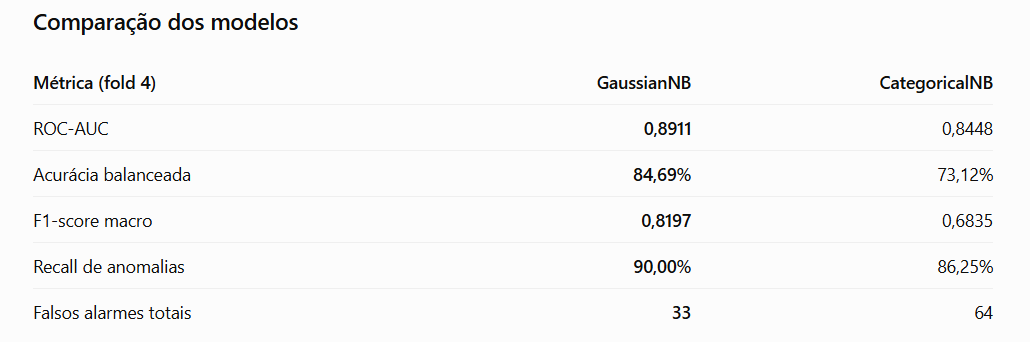

A discretização provavelmente eliminou informações relevantes dos atributos contínuos. Além disso, dividir poucos exemplos de cada classe em várias faixas dificulta a estimativa de probabilidades.
O que faremos agora?
Eu manteria o GaussianNB multiclasse original, com 9 atributos.
Nossa próxima mudança será mais simples: aumentar a quantidade de dados disponíveis para treinamento.
Atualmente, o modelo utiliza três folds para treinamento. Vamos treinar com quatro folds e estimar o limiar por validação cruzada, sem alterar os atributos nem os hiperparâmetros do GaussianNB.
Isso não garante melhora, mas é uma mudança com uma justificativa clara.

In [33]:

from sklearn.base import clone
from sklearn.metrics import roc_curve, roc_auc_score
import numpy as np
import pandas as pd

# Reunir os folds 1, 2, 3 e 4
dados_treino_4 = pd.concat(
    [treino_nb, validacao_nb],
    ignore_index=True
)

X_4 = dados_treino_4[
    atributos_finais
].to_numpy(dtype=float)

y_4 = dados_treino_4["target"].to_numpy(dtype=int)
y_4_bin = (y_4 >= 40).astype(int)
folds_4 = dados_treino_4["fold"].to_numpy()

# Predições fora do fold de treinamento
scores_oof = np.zeros(len(y_4))

for fold in [1, 2, 3, 4]:

    idx_treino = folds_4 != fold
    idx_val = folds_4 == fold

    modelo_cv = clone(modelo_final_nb)

    modelo_cv.fit(
        X_4[idx_treino],
        y_4[idx_treino]
    )

    scores_oof[idx_val] = prob_anomalia_nb(
        modelo_cv,
        X_4[idx_val]
    )

# Encontrar limiar com as predições OOF
fpr, tpr, thresholds = roc_curve(
    y_4_bin, scores_oof
)

validos = np.flatnonzero(np.isfinite(thresholds))

indice = validos[
    np.argmax((tpr - fpr)[validos])
]

limiar_4_folds = float(thresholds[indice])

print("ROC-AUC OOF:",
      round(roc_auc_score(y_4_bin, scores_oof), 4))
print("Limiar escolhido:", round(limiar_4_folds, 4))

# Treinar modelo final com os 4 folds
modelo_nb_4_folds = clone(modelo_final_nb)
modelo_nb_4_folds.fit(X_4, y_4)

print("\nModelo treinado com", len(X_4), "áudios")

ROC-AUC OOF: 0.8092
Limiar escolhido: 0.158

Modelo treinado com 960 áudios


In [34]:

from sklearn.metrics import (
    roc_auc_score, balanced_accuracy_score,
    accuracy_score, f1_score, recall_score,
    confusion_matrix
)

X_teste_final = teste_nb[
    atributos_finais
].to_numpy(dtype=float)

y_teste_final = teste_nb[
    "rotulo_binario"
].to_numpy(dtype=int)

prob_antigo = prob_anomalia_nb(
    modelo_final_nb, X_teste_final
)

prob_novo = prob_anomalia_nb(
    modelo_nb_4_folds, X_teste_final
)

pred_antigo = (
    prob_antigo >= limiar_escolhido
).astype(int)

pred_novo = (
    prob_novo >= limiar_4_folds
).astype(int)

def metricas(nome, prob, pred):
    return {
        "Modelo": nome,
        "ROC_AUC": roc_auc_score(y_teste_final, prob),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_teste_final, pred
        ),
        "Acuracia": accuracy_score(y_teste_final, pred),
        "F1_macro": f1_score(
            y_teste_final, pred, average="macro"
        ),
        "Recall_anomalia": recall_score(
            y_teste_final, pred, pos_label=1
        )
    }

comparacao = pd.DataFrame([
    metricas("Original - 3 folds", prob_antigo, pred_antigo),
    metricas("Novo - 4 folds", prob_novo, pred_novo)
])

print("COMPARAÇÃO:")
display(comparacao.round(4))

print("\nMATRIZ DE CONFUSÃO - MODELO NOVO:")
print(confusion_matrix(y_teste_final, pred_novo))

# Erros nas classes críticas
print("\nERROS POR CLASSE:")

diagnostico = teste_nb[["category"]].copy()
diagnostico["erro_antigo"] = pred_antigo != y_teste_final
diagnostico["erro_novo"] = pred_novo != y_teste_final

display(
    diagnostico.groupby("category")[
        ["erro_antigo", "erro_novo"]
    ].sum().loc[
        ["wind", "helicopter", "fireworks", "pig"]
    ]
)

COMPARAÇÃO:


,Modelo,ROC_AUC,Balanced_Accuracy,Acuracia,F1_macro,Recall_anomalia
0,Original - 3 folds,0.8053,0.7219,0.7500,0.7205,0.6375
1,Novo - 4 folds,0.7999,0.7000,0.7167,0.6919,0.6500



MATRIZ DE CONFUSÃO - MODELO NOVO:
[[120  40]
 [ 28  52]]

ERROS POR CLASSE:


,erro_antigo,erro_novo
category,,
wind,6,7
helicopter,6,6
fireworks,7,7
pig,4,4
